# Modality specificity: native model weights

should be :

- Set the parameters
- Load and print info (electrode count)
- Magnitudes and component-specific thresholds (TODO: different way of thesholding + a brain plot associated directly after)
- Spatial organization of the group-model weights (TODO: put the subejct plot on the same plot, remove the red star, try to find a centroid of the distance, plot the centroid on a brain plot)
add varialbe individual_component = False , component = None. if induvidual component use the solution with normalized semivariograms on the component selected


In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from nilearn import plotting
import seaborn as sns
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

ROOT = Path.cwd()
for path in (ROOT, ROOT.parent, ROOT.parent / 'LB'):
    sys.path.insert(0, str(path))
from vs1_coverage_matching_utils import load_dataset
from vs2_0_cov_models_utils import fit_cov_models
from vs3_1_modality_specificity import threshold_weights, plot_weight_distributions, plot_thresholded_brains


In [2]:
MODEL = 'plssvd'  # 'plssvd', 'separate_pca', 'joint_pca'
MEG_KIND = 'paired_coverage'  # full_average, full_concatenated, coverage_average, paired_coverage, random_control
N_COMPONENTS = 10

MEG_DIR = ROOT / 'MEG' / 'dataMEG'
IEEG_DIR = ROOT / 'ieeg_shortWOBS_fs250'
SFREQ = 250.
CONDITIONS = (1, 2)
BLOCK_SCALING = 'equal_variance'  
MEG_SCALING = 'channel_zscore'
IEEG_MULTIPLIER = 1000.
MEG_COORDINATE_UNIT = 'm'  # unit in the source position CSVs; internal plotting uses mm
METADATA_CSV = None  # optional subject/channel_index/x/y/z table, MNI mm
SEED = 2026
OUTPUT = ROOT / 'out' / 'modality_specificity' / MEG_KIND / MODEL
assert MODEL in ('plssvd', 'separate_pca', 'joint_pca')
assert isinstance(N_COMPONENTS, int) and N_COMPONENTS > 0

# Optional spatial display/summary and clustering modes.
FOLD_HEMISPHERES = False  # Reflect both sides onto TARGET_HEMISPHERE.
TARGET_HEMISPHERE = "left"  # "left" or "right"
CLUSTER_ABSOLUTE_WEIGHTS = False  # Cluster componentwise magnitudes instead of signed weights.


## Load and fit
The iEEG features concatenate all subjects' channels. MEG uses the selected construction: concatenate native sources or average subjects as specified by `MEG_KIND`. The loader averages trials within condition; `condition_mode='average'` then averages conditions. No held-out data are used here.

Without `METADATA_CSV`, the loader uses the original `GetInfo` metadata and its existing coordinate correction. Explicit metadata is already in mm and is not corrected again. Adjust the directory, sampling rate and coordinate units to match your files.


In [3]:
info_files = sorted(IEEG_DIR.glob('*_info.json'))
if not info_files:
    raise FileNotFoundError(f'No iEEG info files in {IEEG_DIR}')
first_info = json.loads(info_files[0].read_text())
ieeg = load_dataset('ieeg', meg_dir=MEG_DIR, ieeg_dir=IEEG_DIR,
    metadata_csv=METADATA_CSV, ieeg_coordinate_unit='mm',
    meg_coordinate_unit=MEG_COORDINATE_UNIT, meg_tmin=float(first_info['time_epoch'][0]),
    sfreq=SFREQ, conditions=CONDITIONS, condition_mode='average',
    meg_scaling=MEG_SCALING, ieeg_scaling='none', ieeg_multiplier=IEEG_MULTIPLIER)
meg = load_dataset(MEG_KIND, reference=ieeg, seed=SEED, condition_mode='average')
# Reuse the established fitting implementation and retain the selected model.
models = fit_cov_models(ieeg, meg, n_components=N_COMPONENTS, block_scaling=BLOCK_SCALING)
model = models[MODEL]
datasets = {'iEEG': ieeg, 'MEG': meg}
weights = {'iEEG': model.ieeg_weights[:, :N_COMPONENTS].copy(),
           'MEG': model.meg_weights[:, :N_COMPONENTS].copy()}
print({name: values.shape for name, values in weights.items()})


{'iEEG': (2576, 10), 'MEG': (2576, 10)}


## Regional coverage: electrode/source counts
Counts use the **same coordinate-based shared labels, clockwise anatomical order and label colours** as the later weight polar charts. Each native dataset feature counts once, before thresholding or spatial averaging. Co-located features are counted separately; for averaged MEG datasets, counts refer to the resulting source rows, not the number of original participant recordings. Missing regions in one modality have count zero; unassigned locations remain explicit. Radial scales are independent so both modalities remain readable. The accompanying table gives exact counts.


In [4]:
from vs3_1_modality_specificity import shared_coordinate_regions, regional_channel_counts, plot_regional_channel_counts
coverage_region_metadata = shared_coordinate_regions(datasets)
region_count_table = regional_channel_counts(coverage_region_metadata)
display(region_count_table.pivot(index='region', columns='modality', values='n_channels').reindex(
    region_count_table.region.drop_duplicates()))
count_fig = plot_regional_channel_counts(region_count_table)
#display(count_fig)
OUTPUT.mkdir(parents=True, exist_ok=True)
region_count_table.to_csv(OUTPUT / 'regional_channel_counts.csv', index=False)
count_fig.savefig(OUTPUT / 'regional_channel_counts.png', dpi=180, bbox_inches='tight')
for modality, metadata in coverage_region_metadata.items():
    metadata.to_csv(OUTPUT / f'{modality.lower()}_coverage_region_labels.csv', index=False)
plt.close(count_fig)


[fetch_atlas_aal] Dataset found in /users/barbara/nilearn_data/aal_SPM12

modality,MEG,iEEG
region,,
A1,12,20
STG,141,146
MTG,289,303
TP,79,88
VS,380,361
HPC,86,89
PHC,52,50
AMY,19,22
S1,65,71


## Magnitudes and component-specific thresholds

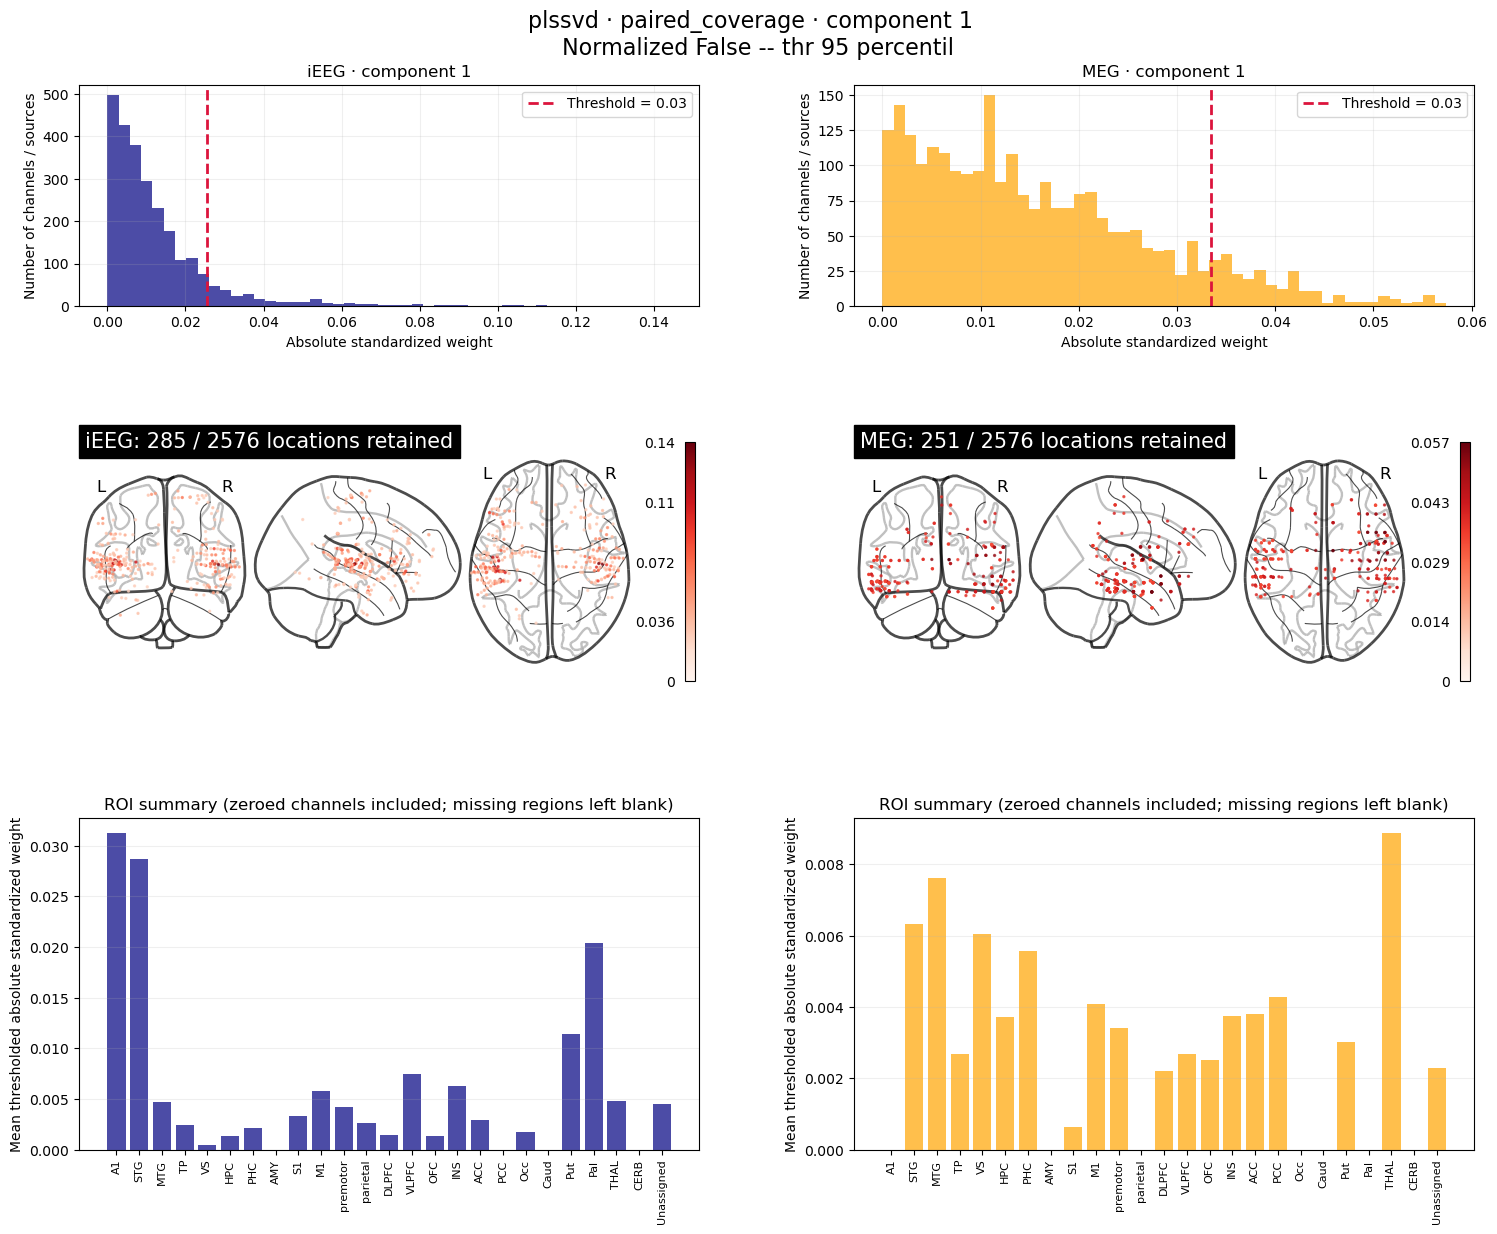

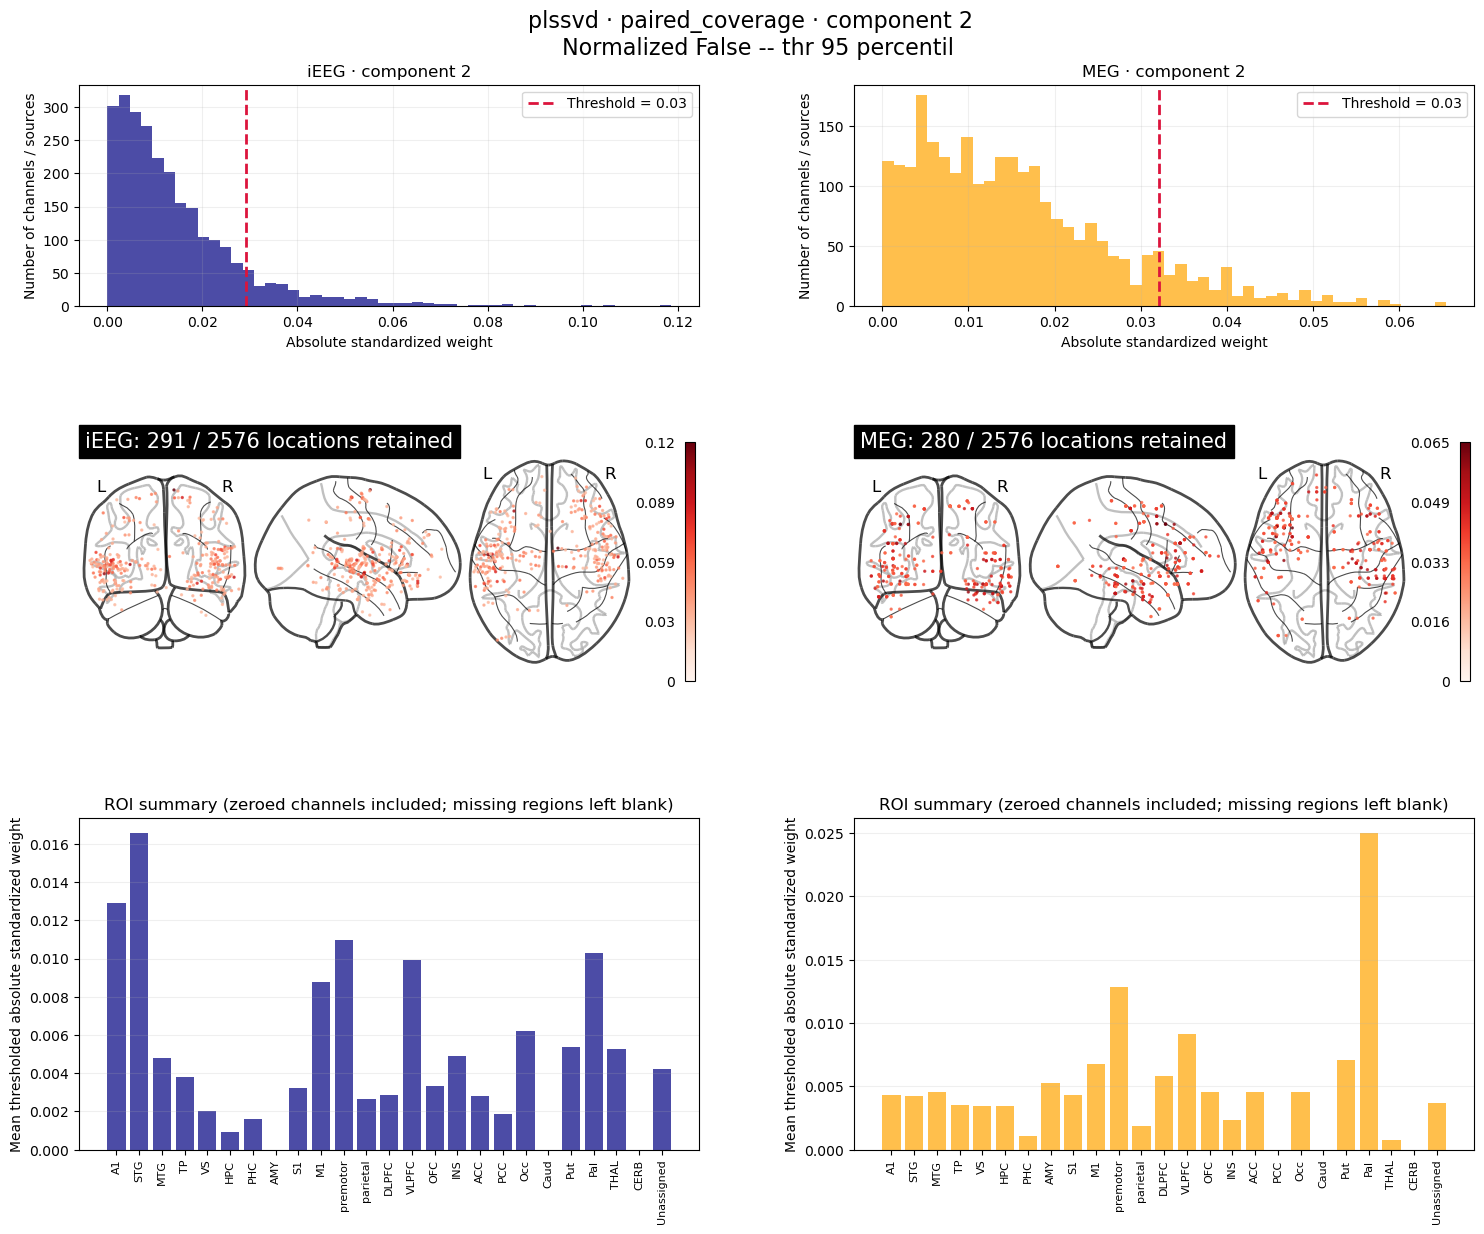

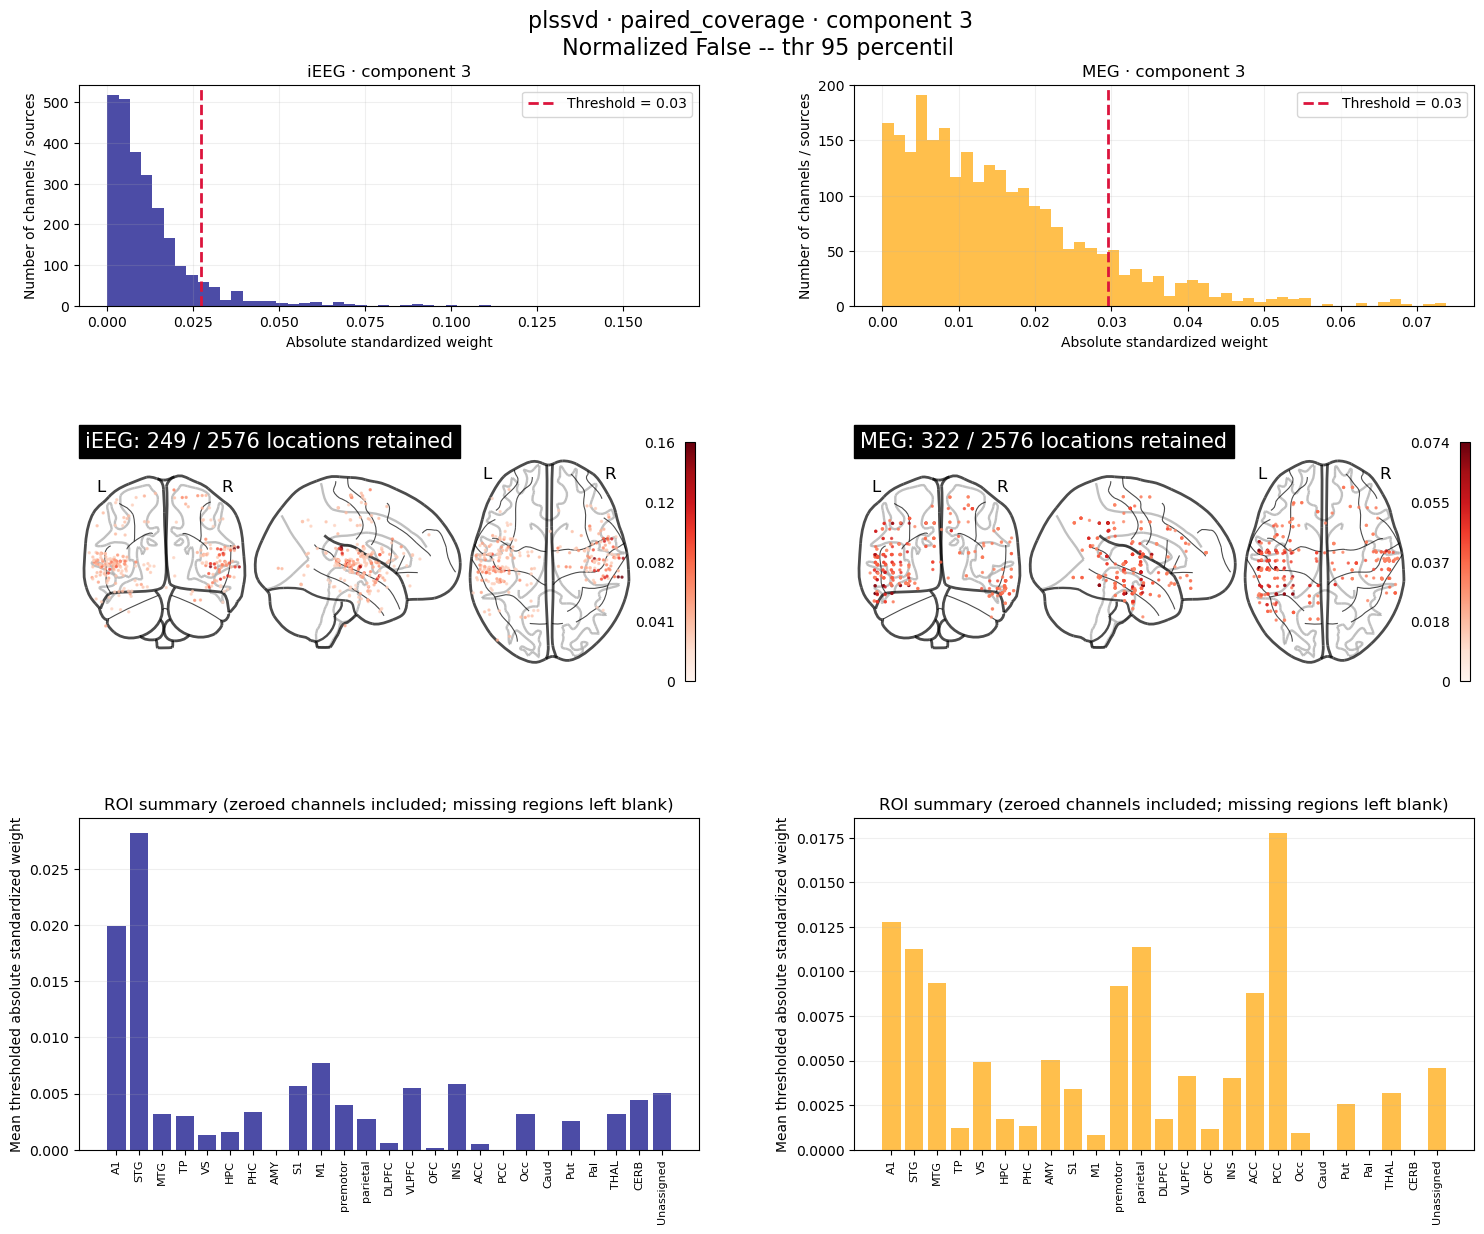

In [5]:
from nilearn import plotting
normalized = False
percent = 95

components_to_plot = 3
color = {'iEEG': 'navy','MEG': 'orange'}

regions = region_count_table.region.drop_duplicates().tolist()
OUTPUT.mkdir(parents=True, exist_ok=True)

for compo in range(components_to_plot):
    overview_fig, ax = plt.subplots(3, 2, figsize=(18, 15),gridspec_kw={'height_ratios': [1, 1.2, 1.5]})
    overview_fig.subplots_adjust(top=0.93, bottom=0.22, hspace=0.45, wspace=0.25)
    for column, dataset_ in enumerate(['iEEG', 'MEG']):
        # Standardize
        if normalized : 
            mean = np.mean(weights[dataset_], axis=0)
            std = np.std(weights[dataset_], axis=0)
            norm = np.divide(weights[dataset_] - mean, std,
                            out=np.zeros_like(weights[dataset_], dtype=float), where=std > 0)
            magnitude = abs(norm[:, compo])
            q3 = np.percentile(norm[:, compo], percent)
        else :
            magnitude = abs(weights[dataset_][:, compo])
            q3 = np.percentile(weights[dataset_][:, compo], percent)
        
        selected = (magnitude >= q3) & (magnitude > 0)
        thresholded = np.where(selected, magnitude, 0.)

        metadata = coverage_region_metadata[dataset_].reset_index(drop=True)
        coordinates = metadata[['x', 'y', 'z']].to_numpy(dtype=float)  # MNI mm
        if len(metadata) != len(magnitude) or not np.isfinite(coordinates).all():
            raise ValueError(f'{dataset_}: check coordinate rows and finite MNI values.')

        # Hist
        ax[0, column].hist(magnitude, bins=50, color=color[dataset_], alpha=0.7)
        ax[0, column].axvline(q3, color='crimson', linestyle='--', linewidth=2,
                             label=f'Threshold = {q3:.2f}')
        ax[0, column].set(title=f'{dataset_} · component {compo + 1}',
                          xlabel='Absolute standardized weight', ylabel='Number of channels / sources')
        ax[0, column].legend()
        ax[0, column].grid(alpha=0.2)

        # Brain plot
        if selected.any():
            plotting.plot_markers(thresholded[selected], coordinates[selected],
                figure=overview_fig, axes=ax[1, column], display_mode='ortho',
                node_size=2, 
                node_cmap='Reds', 
                node_vmin=0,
                node_vmax=float(np.max(magnitude)), 
                colorbar=True,
                title=f'{dataset_}: {selected.sum()} / {len(selected)} locations retained')
        else:
            plotting.plot_glass_brain(None, figure=overview_fig, axes=ax[1, column],
                                     display_mode='ortho', title=f'{dataset_}: no locations retained')

        # ROIs chart
        roi_table = pd.DataFrame({'region': metadata.region_shared.fillna('Unassigned'),
                                  'weight': thresholded})
        roi_mean = roi_table.groupby('region').weight.mean().reindex(regions)
        ax[2, column].bar(np.arange(len(regions)), roi_mean.to_numpy(),
                         color=color[dataset_], alpha=0.7)
        ax[2, column].set(xticks=np.arange(len(regions)), xticklabels=regions,
                          ylabel='Mean thresholded absolute standardized weight',
                          title='ROI summary (zeroed channels included; missing regions left blank)')
        ax[2, column].tick_params(axis='x', labelrotation=90, labelsize=8)
        ax[2, column].grid(axis='y', alpha=0.2)

    overview_fig.suptitle(f'{MODEL} · {MEG_KIND} · component {compo + 1} \n Normalized {normalized} -- thr {percent} percentil', fontsize=16)
    overview_fig.savefig(OUTPUT / f'weight_overview_component_{compo + 1}_{str(normalized)[0]}_thr{percent}.png',
                         dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(overview_fig)


## Paired-coverage spatial profile organization and weight patches
This analysis **always constructs paired_coverage MEG**, independently of `MEG_KIND` above. Choose PLSSVD, separate PCA, or joint PCA below. Computation is implemented in `vs3_1_spatial_profiles.py`; saved tables can be reused without refitting when inputs and parameters match.

Profiles use componentwise absolute weights normalized to unit length: cosine(|wᵢ|, |wⱼ|), not |cosine(wᵢ,wⱼ)|. Magnitude is analyzed separately with a variance-normalized semivariogram. The spatial scope determines the normalization and shuffle groups, as described below.

Set `PROFILE_SPATIAL_SCOPE` to choose the analysis:

- **`'within_participant'` (default):** pairs and patches stay within each matched participant block and hemisphere. Magnitude variance and profile shuffles are computed within participant/hemisphere. Participant curves receive equal weight; bands are paired-participant bootstrap intervals conditional on the fitted model.
- **`'pooled'`:** treat all retained participants as one analysis block, separately for each hemisphere. Include both within- and cross-participant pairs, giving every eligible pair equal weight. Normalize magnitude variance and shuffle whole profiles across the pooled hemisphere. Patches may contain locations from multiple participants. No participant bootstrap confidence bands are reported for this single pooled block; `n_subjects` counts contributing original participants and `n_analysis_units` is one for a nonempty bin. Original participant IDs remain in the membership table's `participant` column. These are pooled MNI patterns, not observations from one individual brain.

**Optional hemisphere folding:** set `PROFILE_FOLD_HEMISPHERES = True` and choose `PROFILE_TARGET_HEMISPHERE = 'left'` or `'right'`. Both electrode and MEG source coordinates are reflected across the MNI midline: x becomes `-abs(x)` for left or `abs(x)` for right; y and z are unchanged. This affects distances, patches, medoids, and brain plots, not just display. Original left/right locations then share one spatial/shuffle/variance group per analysis block. With `within_participant`, participants remain separate; with `pooled`, all retained locations share one group. These distances describe folded spatial separation, not original interhemispheric distances.

Original-coordinate matching exclusions and duplicate removal happen before folding. Distinct measurements that become co-located remain retained, but their zero-distance pairs are excluded from the curves. Membership tables preserve original coordinates and hemisphere. Native, folded-left, and folded-right results use separate cache directories. Model weights and source matching are unchanged.

Both modes require corresponding pairs to occupy the same distance bin in both modalities. Duplicate MEG coordinate matches **within each original participant** are dropped jointly, keeping the first electrode correspondence; zero profiles, mismatched hemispheres, midline rows, and zero-distance pairs are excluded. Participant bootstrap bands in the default mode are not independent-pair confidence intervals or trial-bootstrap uncertainty. Results are cached in separate scope directories. Pooled mode can require substantially more time and memory because pair counts grow quadratically. Inspect the audit and counts: matching improves comparability but does not remove differences in measurement resolution or reconstruction smoothness.

Patches are computed separately within each analysis block/hemisphere using spatial adjacency and a minimum cosine similarity for **every pair** within a patch. This avoids similarity chaining. Stars identify actual member locations (spatial medoids). Patch coherence, boundary contrast, extent, and 80%-source-retention Jaccard stability are descriptive; they do not validate activity regions. Source-deletion stability is not PCA-refit stability. Sparse paired coverage cannot establish full cortical patch boundaries. Vary radius, similarity threshold, component count, and the optional low-norm exclusion to assess sensitivity.

**Patch metric:** `PROFILE_PATCH_METRIC = 'cosine'` uses a minimum absolute-profile cosine similarity. Choose `'magnitude_semivariance'` to require `(||w_i|| - ||w_j||)^2 / (2 Var(||w||)) <= PROFILE_PATCH_MAX_SEMIVARIANCE` for every member pair. Variance uses all retained locations in the analysis block/hemisphere, and is held fixed during source-deletion resampling. Zero-variance groups cannot be normalized and produce no magnitude patches. The illustrative threshold 0.10 is a tuning parameter, not a significance threshold. Both modes retain spatial adjacency and prevent chaining. Magnitude similarity does not imply high weights or similar component proportions.

For magnitude patches, the metric histograms show within-patch semivariance (lower is more homogeneous), magnitude contrast (boundary minus within-patch semivariance), and stability. Cosine coherence and cosine contrast remain explicitly available in the patch table. The distance-profile curves are unchanged by the patch criterion. Signed weights from this exact fit are cached for the inline per-component distribution plot.


In [6]:
# Reload the implementation so an existing kernel uses updated function signatures.
import importlib
import vs3_1_spatial_profiles as spatial_profiles_module
spatial_profiles_module = importlib.reload(spatial_profiles_module)
from vs3_1_spatial_profiles import run_analysis, plot_analysis

PROFILE_MODEL = 'plssvd'  # 'plssvd', 'separate_pca', 'joint_pca'
PROFILE_SPATIAL_SCOPE = 'within_participant'  # 'within_participant' or 'pooled'
PROFILE_FOLD_HEMISPHERES = True  # True reflects both sides into the target hemisphere
PROFILE_TARGET_HEMISPHERE = 'left'  # 'left' or 'right'
PROFILE_N_COMPONENTS = 2  # >= 2; independent of earlier N_COMPONENTS
PROFILE_DISTANCE_BINS_MM = np.arange(0, 101, 10)
PROFILE_PERMUTATIONS = 199
PROFILE_BOOTSTRAPS = 500
PROFILE_PATCH_RADIUS_MM = 15.
PROFILE_PATCH_METRIC = 'cosine'  # 'cosine' or 'magnitude_semivariance'
PROFILE_PATCH_SIMILARITY = 0.95  # minimum cosine similarity; cosine mode only
PROFILE_PATCH_MAX_SEMIVARIANCE = 0.10  # maximum normalized magnitude semivariance; magnitude mode only
PROFILE_MIN_PATCH_SOURCES = 3
PROFILE_PATCH_RESAMPLES = 30
PROFILE_MIN_NORM_QUANTILE = 0.25  # e.g. .1 excludes the weakest 10% of positive profiles
RECOMPUTE_PROFILE_SPATIAL = True  # first run computes; set True after changing settings
PROFILE_HEMISPHERE_MODE = f'folded_{PROFILE_TARGET_HEMISPHERE}' if PROFILE_FOLD_HEMISPHERES else 'native'
PROFILE_OUTPUT = ROOT / 'out' / 'spatial_profiles' / 'paired_coverage' / PROFILE_MODEL / f'k{PROFILE_N_COMPONENTS}' / PROFILE_SPATIAL_SCOPE / PROFILE_HEMISPHERE_MODE / PROFILE_PATCH_METRIC

profile_spatial = run_analysis(ieeg, model=PROFILE_MODEL,
    n_components=PROFILE_N_COMPONENTS, seed=SEED, block_scaling=BLOCK_SCALING,
    spatial_scope=PROFILE_SPATIAL_SCOPE,
    fold_hemispheres=PROFILE_FOLD_HEMISPHERES, target_hemisphere=PROFILE_TARGET_HEMISPHERE,
    output_dir=PROFILE_OUTPUT, recompute=RECOMPUTE_PROFILE_SPATIAL,
    bin_edges=PROFILE_DISTANCE_BINS_MM, n_permutations=PROFILE_PERMUTATIONS,
    n_bootstrap=PROFILE_BOOTSTRAPS, patch_radius_mm=PROFILE_PATCH_RADIUS_MM,
    patch_metric=PROFILE_PATCH_METRIC, patch_max_semivariance=PROFILE_PATCH_MAX_SEMIVARIANCE,
    patch_similarity=PROFILE_PATCH_SIMILARITY, min_patch_size=PROFILE_MIN_PATCH_SOURCES,
    patch_resamples=PROFILE_PATCH_RESAMPLES, min_norm_quantile=PROFILE_MIN_NORM_QUANTILE)
display(profile_spatial['audit'])


,subject,spatial_scope,patch_metric,fold_hemispheres,target_hemisphere,n_participants,n_original_features,n_matched_features,n_matched_pairs
0,BJH026,within_participant,cosine,True,left,1,70,15,88
1,BJH027,within_participant,cosine,True,left,1,137,31,362
2,BJH029,within_participant,cosine,True,left,1,133,36,472
3,BJH030,within_participant,cosine,True,left,1,97,33,402
4,BJH039,within_participant,cosine,True,left,1,66,18,129
5,BJH041,within_participant,cosine,True,left,1,56,15,80
6,BJH042,within_participant,cosine,True,left,1,91,35,428
7,BJH045,within_participant,cosine,True,left,1,155,52,828
8,BJH046,within_participant,cosine,True,left,1,153,55,915
9,BJH049,within_participant,cosine,True,left,1,80,33,413


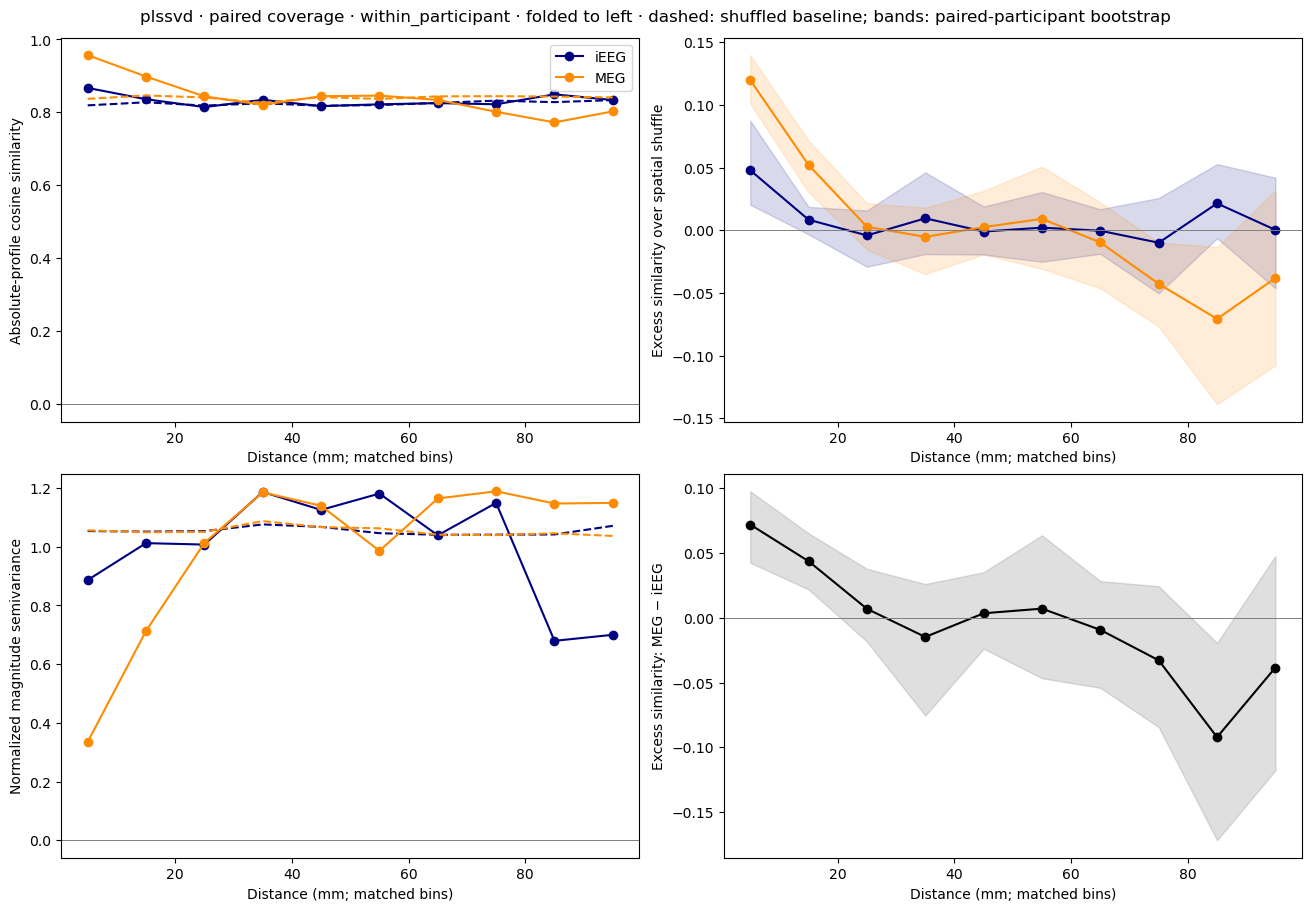

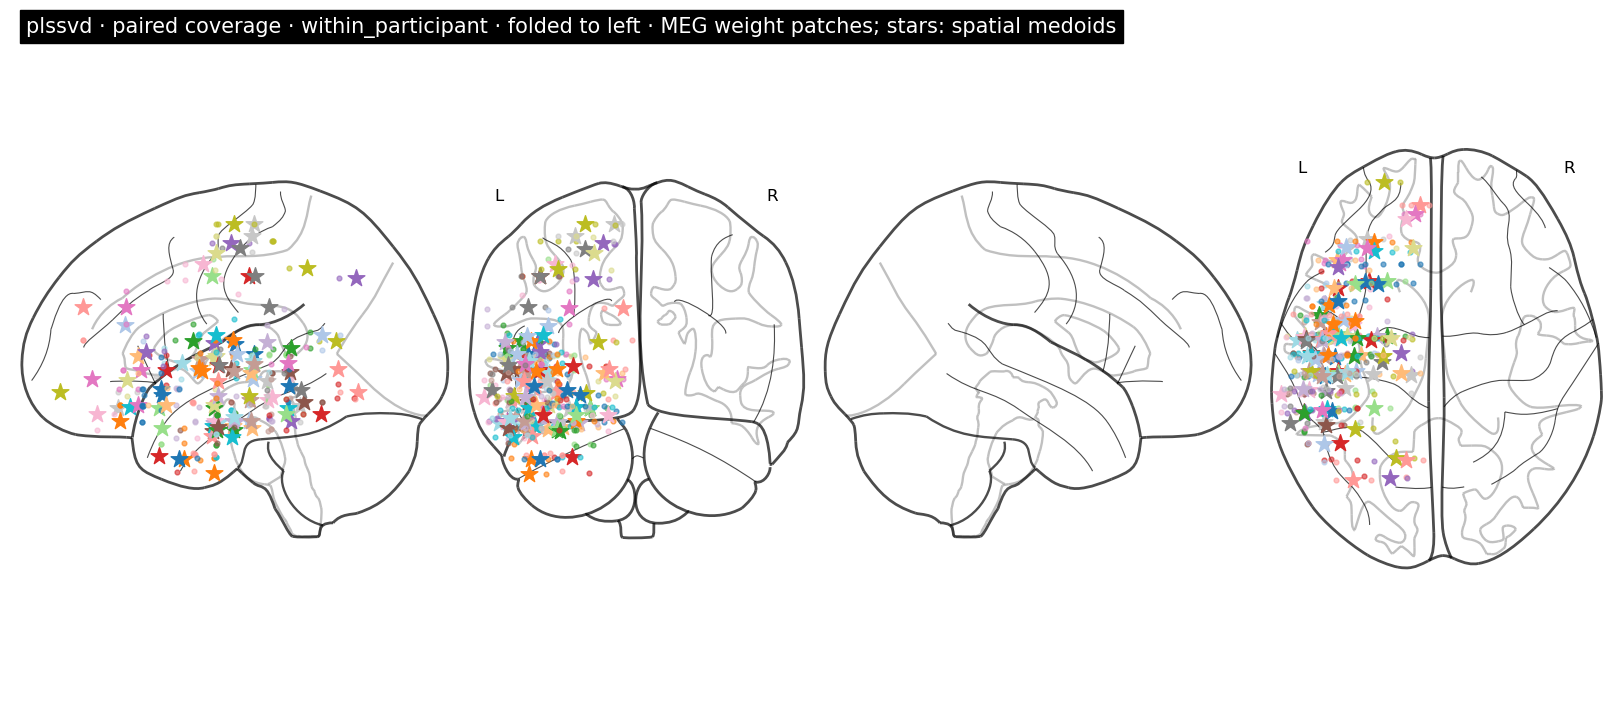

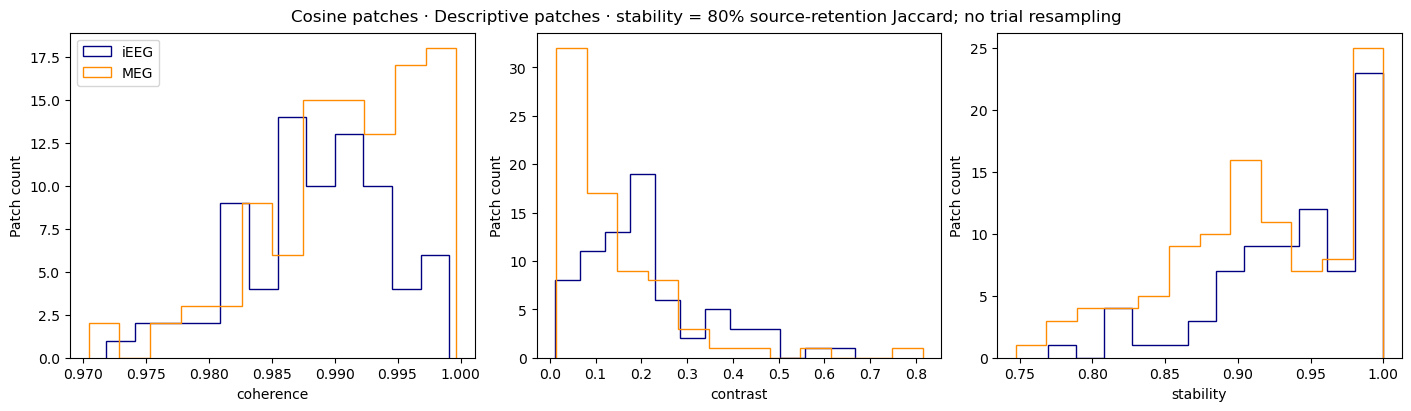

,modality,subject,hemisphere,patch_id,n_sources,patch_metric,magnitude_variance,within_magnitude_semivariance,boundary_magnitude_semivariance,magnitude_contrast,coherence,boundary_similarity,contrast,radius_rms_mm,diameter_mm,stability,medoid_x,medoid_y,medoid_z
0,MEG,BJH026,left,BJH026_left_4,4,cosine,0.0,0.000,NaN,NaN,0.986,NaN,NaN,8.505,22.820,0.894,-43.167,-15.575,12.130
1,iEEG,BJH027,left,BJH027_left_10,3,cosine,0.0,0.192,0.056,-0.136,0.986,0.890,0.096,6.032,12.820,1.000,-59.600,-37.650,-14.200
2,iEEG,BJH027,left,BJH027_left_11,6,cosine,0.0,0.290,0.220,-0.070,0.985,0.319,0.666,7.299,18.294,1.000,-44.900,-3.950,-41.200
3,iEEG,BJH027,left,BJH027_left_16,3,cosine,0.0,4.594,0.859,-3.735,0.999,0.866,0.132,8.063,19.630,0.963,-49.600,-22.400,-3.050
4,iEEG,BJH027,left,BJH027_left_25,4,cosine,0.0,0.093,0.143,0.050,0.982,0.843,0.138,6.018,15.820,0.901,-31.650,-13.500,-24.800
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175,iEEG,SLCH024,left,SLCH024_left_1,4,cosine,0.0,0.072,0.246,0.174,0.987,0.757,0.230,4.180,11.262,1.000,-32.175,4.468,-39.434
176,iEEG,SLCH024,left,SLCH024_left_11,3,cosine,0.0,0.170,NaN,NaN,0.982,NaN,NaN,6.799,14.241,1.000,-57.116,-47.044,-4.035
177,MEG,SLCH024,left,SLCH024_left_1,4,cosine,0.0,0.085,0.096,0.011,0.995,0.713,0.282,6.816,16.383,1.000,-41.760,8.781,-37.744
178,MEG,SLCH024,left,SLCH024_left_14,3,cosine,0.0,0.102,0.185,0.083,0.994,0.952,0.042,5.889,12.668,1.000,-47.658,-53.230,15.719


,distance_mm,meg_minus_ieeg,ci_low,ci_high
0,5.0,0.0720,0.0425,0.0977
1,15.0,0.0437,0.0218,0.0652
2,25.0,0.0069,-0.0184,0.0378
3,35.0,-0.0148,-0.0755,0.0261
4,45.0,0.0035,-0.0238,0.0352
5,55.0,0.0071,-0.0466,0.0637
6,65.0,-0.0093,-0.0541,0.0283
7,75.0,-0.0328,-0.0844,0.0244
8,85.0,-0.0922,-0.1718,-0.0194
9,95.0,-0.0384,-0.1178,0.0477


In [7]:
# Redraw from computed/cached tables only; no fit or spatial computation here.
for name, figure in plot_analysis(profile_spatial, title=f'{PROFILE_MODEL} · paired coverage · {PROFILE_SPATIAL_SCOPE}').items():
    figure.savefig(PROFILE_OUTPUT / f'{name}.png', dpi=180, bbox_inches='tight')
    display(figure)
    plt.close(figure)
display(profile_spatial['patches'].round(3))
display(profile_spatial['difference'].round(4))


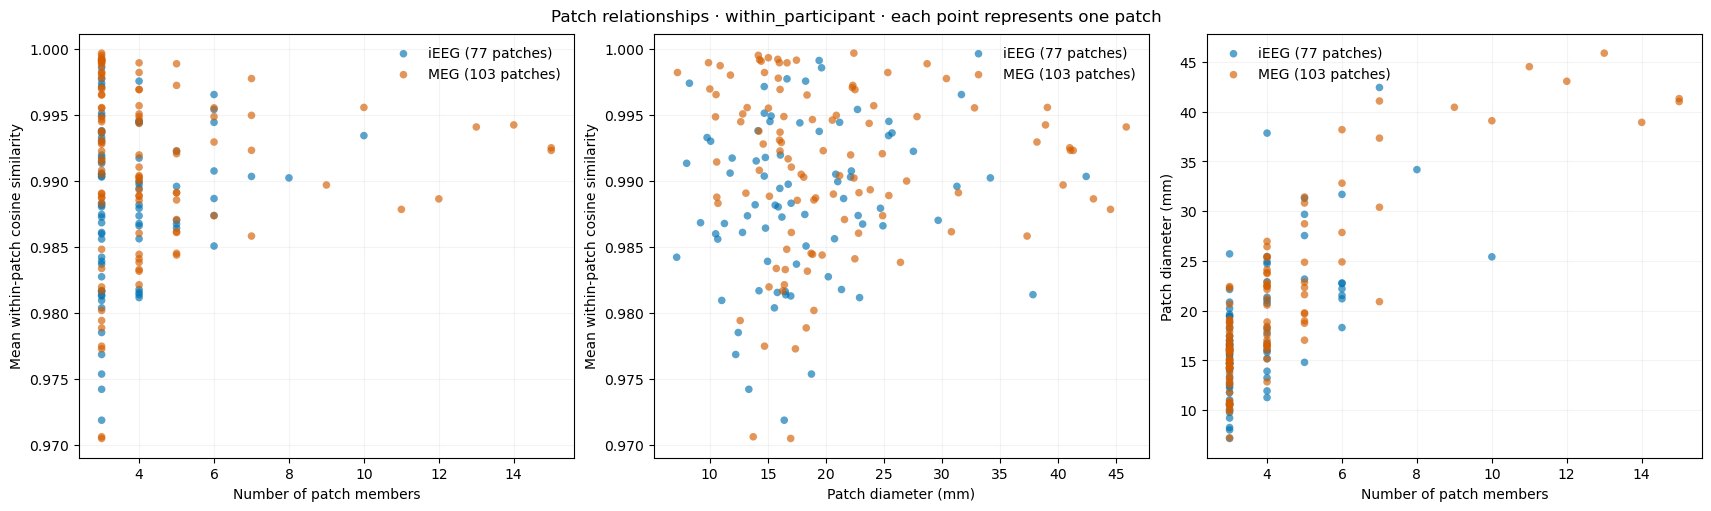

In [8]:
# Pairwise scatter plots of patch size, mean within-patch metric, and spatial extent.
PATCH_DISTRIBUTION_METRIC = 'auto'  # 'auto', 'coherence', or 'within_magnitude_semivariance'

patch_distribution_table = profile_spatial['patches'].copy()

if PATCH_DISTRIBUTION_METRIC == 'auto':
    patch_distribution_modes = patch_distribution_table['patch_metric'].unique()
    patch_distribution_metric = ('within_magnitude_semivariance'if patch_distribution_modes[0] == 'magnitude_semivariance' else 'coherence')
else:
    patch_distribution_metric = PATCH_DISTRIBUTION_METRIC


patch_distribution_metric_label = ('Mean within-patch cosine similarity' if patch_distribution_metric == 'coherence' else 'Mean within-patch normalized magnitude semivariance')

patch_distribution_pairs = [('n_sources', patch_distribution_metric, 'Number of patch members', patch_distribution_metric_label),
                            ('diameter_mm', patch_distribution_metric, 'Patch diameter (mm)', patch_distribution_metric_label),
                            ('n_sources', 'diameter_mm', 'Number of patch members', 'Patch diameter (mm)')]

patch_distribution_colors = {'iEEG': '#0072B2', 'MEG': '#D55E00'}
patch_distribution_figure, patch_distribution_axes = plt.subplots(
    1, 3, figsize=(17, 5), layout='constrained')

for axis, (x_column, y_column, x_label, y_label) in zip(
        patch_distribution_axes, patch_distribution_pairs):
    patch_distribution_valid = patch_distribution_table.replace(
        [np.inf, -np.inf], np.nan).dropna(subset=[x_column, y_column])
    for modality, color in patch_distribution_colors.items():
        patch_distribution_subset = patch_distribution_valid.loc[
            patch_distribution_valid.modality.eq(modality)]
        axis.scatter(
            patch_distribution_subset[x_column], patch_distribution_subset[y_column],
            color=color, s=30, alpha=0.65, edgecolors='none',
            label=f'{modality} ({len(patch_distribution_subset)} patches)')
    if patch_distribution_valid.empty:
        axis.text(0.5, 0.5, 'No finite values', ha='center', va='center',
                  transform=axis.transAxes)
    axis.set(xlabel=x_label, ylabel=y_label)
    axis.set_axisbelow(True)
    axis.grid(alpha=0.15)
    axis.legend(frameon=False)

patch_distribution_scope = (profile_spatial['audit']['spatial_scope'].iloc[0]
    if 'spatial_scope' in profile_spatial['audit'] else 'unspecified scope')
patch_distribution_figure.suptitle(
    f'Patch relationships · {patch_distribution_scope} · each point represents one patch')
display(patch_distribution_figure)
plt.close(patch_distribution_figure)


In [9]:
df_to_check = profile_spatial['patches'].query('n_sources > 150')

In [10]:

for PATCH_ID, PATCH_MODALITY in zip(df_to_check.patch_id, df_to_check.modality):
    selected_patch_table = profile_spatial['patches'].loc[profile_spatial['patches']['modality'].eq(PATCH_MODALITY)]
    selected_patch_id = selected_patch_table.iloc[0]['patch_id'] if PATCH_ID is None else PATCH_ID
    selected_patch_table = selected_patch_table.loc[selected_patch_table['patch_id'].eq(selected_patch_id)]
    selected_patch_members = profile_spatial['memberships'].loc[profile_spatial['memberships']['modality'].eq(PATCH_MODALITY)& profile_spatial['memberships']['patch_id'].eq(selected_patch_id)]

    selected_patch_row = selected_patch_table.iloc[0]
    selected_patch_color = 'darkorange' if PATCH_MODALITY == 'MEG' else 'navy'
    selected_patch_title = (f'{PATCH_MODALITY} · {selected_patch_id} · {len(selected_patch_members)} members'
        '\nDots: patch members; star: spatial medoid')

    # Use the saved analysis coordinates, including hemisphere folding when enabled.
    if ('fold_hemispheres' in profile_spatial['audit']and profile_spatial['audit']['fold_hemispheres'].eq(True).all()):
        selected_patch_title += f" · folded to {profile_spatial['audit']['target_hemisphere'].iloc[0]}"

    selected_patch_figure = plt.figure(figsize=(14, 5))
    selected_patch_brain = plotting.plot_glass_brain(None, figure=selected_patch_figure, display_mode='ortho', title=selected_patch_title)
    selected_patch_brain.add_markers(selected_patch_members[['x', 'y', 'z']].to_numpy(dtype=float),marker_color=selected_patch_color, marker_size=45, alpha=0.8)
    selected_patch_brain.add_markers(selected_patch_table[['medoid_x', 'medoid_y', 'medoid_z']].to_numpy(dtype=float),marker_color='crimson', marker='*', marker_size=220)
    display(selected_patch_figure)
    plt.close(selected_patch_figure)
#display(selected_patch_table.round(3))


In [11]:
# Component weight distributions for the patch(es) displayed in the preceding cell.
patch_weight_columns = sorted([column for column in profile_spatial['weights'] if column.startswith('weight_')],key=lambda column: int(column.split('_')[-1]))

for distribution_patch_id, distribution_modality in zip(df_to_check.patch_id, df_to_check.modality):
    distribution_members = profile_spatial['memberships'].loc[profile_spatial['memberships'].modality.eq(distribution_modality)& profile_spatial['memberships'].patch_id.eq(distribution_patch_id)]
    distribution_weights = distribution_members[['modality', 'feature_row']].merge(profile_spatial['weights'], on=['modality', 'feature_row'], how='left', validate='one_to_one')
    distribution_values = distribution_weights[patch_weight_columns].to_numpy(dtype=float)
    distribution_values = np.abs(distribution_values)

    distribution_edges = np.histogram_bin_edges(distribution_values.ravel(), bins=15)
    distribution_ncols = min(4, len(patch_weight_columns))

    distribution_nrows = int(np.ceil(len(patch_weight_columns) / distribution_ncols))
    distribution_figure, distribution_axes = plt.subplots(distribution_nrows, distribution_ncols+1, figsize=(4 * distribution_ncols, 3.5 * distribution_nrows),squeeze=False, sharex=True, sharey=True, layout='constrained')
    
    for ic in range(distribution_ncols):
        distribution_axes[0][ic].hist(distribution_values[:, ic], bins=distribution_edges,color=patch_distribution_colors[distribution_modality], alpha=0.75, edgecolor='white')
        distribution_axes[0][ic].set(title=f'Component {ic + 1}',xlabel='Absolute model weight', ylabel='Patch member count')
        distribution_axes[0][ic].set_xlim(0, 0.15)
    
    distribution_axes[0][2].hist(np.linalg.norm(distribution_values, axis=1), bins=distribution_edges, color='k', alpha=0.75, edgecolor='white')
    distribution_axes[0][2].set(title=f'Norme',xlabel='Absolute model weight', ylabel='Patch member count')

    distribution_figure.suptitle( f'{distribution_modality} · {distribution_patch_id} · {len(distribution_values)} members')
    display(distribution_figure)
    plt.close(distribution_figure)


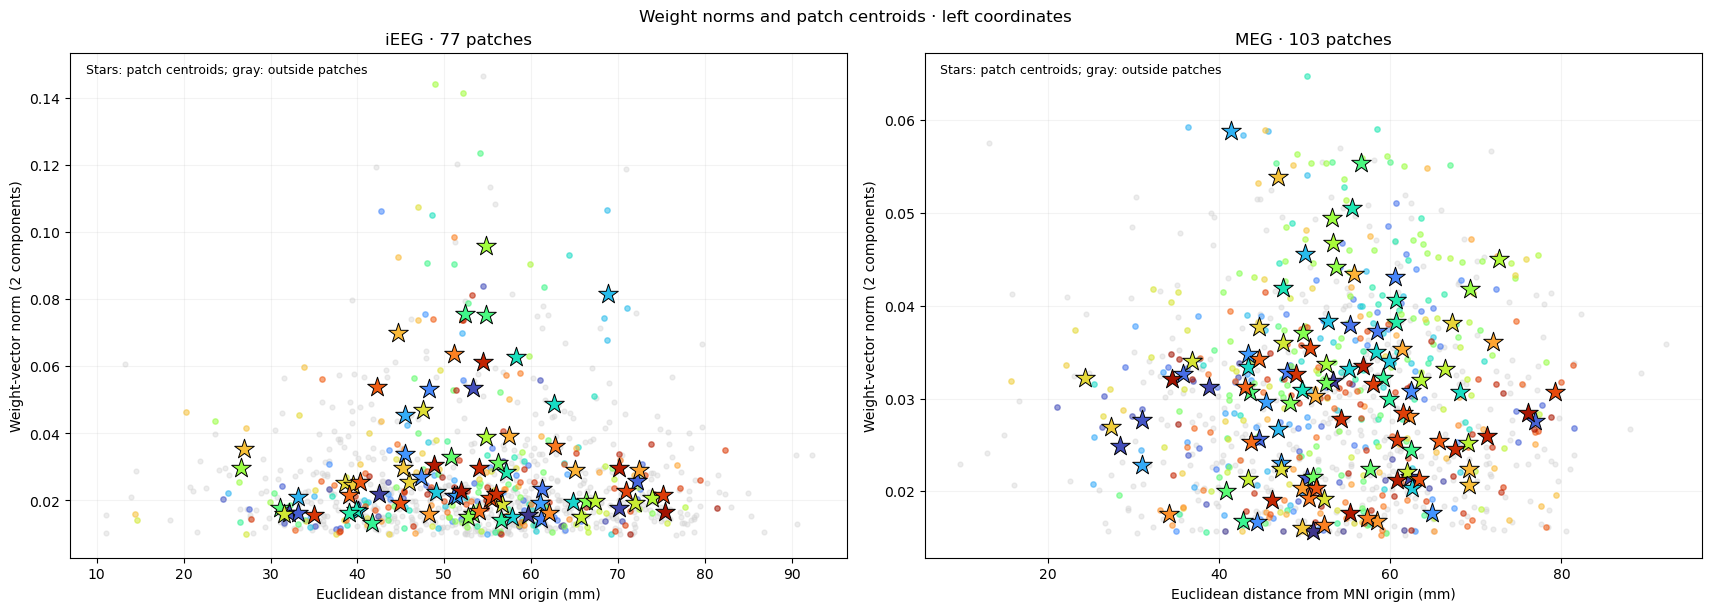

,modality,patch_id,n_members,x,y,z,distance_mm,mean_weight_norm
0,iEEG,BJH027_left_11,6,-44.141667,-3.658333,-39.900000,59.614429,0.015670
1,iEEG,BJH027_left_25,4,-32.212500,-14.375000,-23.762500,42.531661,0.021990
2,iEEG,BJH027_left_10,3,-58.483333,-34.650000,-16.983333,70.066799,0.017624
3,iEEG,BJH027_left_16,3,-48.350000,-22.383333,-2.983333,53.363249,0.053491
4,iEEG,BJH029_left_0,4,-25.762500,-5.837500,-18.312500,32.142347,0.016240
...,...,...,...,...,...,...,...,...
175,MEG,SLCH020_left_16,4,-18.621941,-7.126915,53.266056,56.875674,0.033453
176,MEG,SLCH020_left_33,4,-54.908688,-11.263497,-23.494576,60.776850,0.021166
177,MEG,SLCH024_left_1,4,-39.946019,6.854255,-37.689648,55.345956,0.017679
178,MEG,SLCH024_left_14,3,-50.005038,-55.654525,13.603230,76.045893,0.028409


In [12]:
# Weight norm versus distance from the MNI origin; stars mark spatial patch centroids.
# Star height = mean member norm (not the norm of the mean weight vector).
PATCH_ORIGIN_MM = np.array([0., 0., 0.])
patch_radial_columns = sorted(
    [c for c in profile_spatial['weights'] if c.startswith('weight_')],
    key=lambda c: int(c.split('_')[-1]))
patch_radial_table = profile_spatial['weights'].copy()
patch_radial_table['weight_norm'] = np.linalg.norm(
    patch_radial_table[patch_radial_columns].to_numpy(float), axis=1)

# Recover coordinates for every retained feature, including features outside patches.
# The patch analysis uses paired_coverage in original electrode row order.
from vs1_coverage_matching_utils import load_dataset
patch_radial_meg = load_dataset('paired_coverage', reference=ieeg,
                               seed=SEED, condition_mode='average')
patch_radial_metadata = {'iEEG': ieeg.metadata, 'MEG': patch_radial_meg.metadata}
patch_radial_folded = ('fold_hemispheres' in profile_spatial['audit']
    and profile_spatial['audit']['fold_hemispheres'].eq(True).all())
patch_radial_target = (profile_spatial['audit']['target_hemisphere'].iloc[0]
                       if patch_radial_folded else 'native')
for modality, metadata in patch_radial_metadata.items():
    selected_rows = patch_radial_table.modality.eq(modality)
    feature_rows = patch_radial_table.loc[selected_rows, 'feature_row'].to_numpy(int)
    coordinates = metadata.iloc[feature_rows][['x', 'y', 'z']].to_numpy(float).copy()
    if patch_radial_folded:
        coordinates[:, 0] = (-1 if patch_radial_target == 'left' else 1) * np.abs(coordinates[:, 0])
    patch_radial_table.loc[selected_rows, ['x', 'y', 'z']] = coordinates

patch_radial_members = profile_spatial['memberships'][
    ['modality', 'feature_row', 'patch_id', 'x', 'y', 'z']]
patch_radial_table = patch_radial_table.merge(
    patch_radial_members, on=['modality', 'feature_row'], how='left',
    suffixes=('', '_saved'), validate='one_to_one')
patch_radial_assigned = patch_radial_table.patch_id.notna()
# Detect mismatched cached analysis versus the current paired-coverage metadata.
if not np.allclose(
        patch_radial_table.loc[patch_radial_assigned, ['x', 'y', 'z']].to_numpy(float),
        patch_radial_table.loc[patch_radial_assigned, ['x_saved', 'y_saved', 'z_saved']].to_numpy(float)):
    raise ValueError('Coordinates differ from saved patches. Rerun the patch analysis with the current inputs.')
patch_radial_table['distance_mm'] = np.linalg.norm(
    patch_radial_table[['x', 'y', 'z']].to_numpy(float) - PATCH_ORIGIN_MM, axis=1)
patch_radial_centroids = []
patch_radial_figure, patch_radial_axes = plt.subplots(
    1, 2, figsize=(17, 6), layout='constrained')
for axis, modality in zip(patch_radial_axes, ('iEEG', 'MEG')):
    modality_points = patch_radial_table.loc[patch_radial_table.modality.eq(modality)]
    unassigned_points = modality_points.loc[modality_points.patch_id.isna()]
    axis.scatter(unassigned_points.distance_mm, unassigned_points.weight_norm,
                 color='lightgray', s=12, alpha=.4, label='Outside retained patches')
    patch_ids = modality_points.patch_id.dropna().unique()
    patch_colors = plt.get_cmap('turbo')(np.linspace(.05, .95, max(1, len(patch_ids))))
    for patch_id, patch_color in zip(patch_ids, patch_colors):
        members = modality_points.loc[modality_points.patch_id.eq(patch_id)]
        centroid_xyz = members[['x', 'y', 'z']].mean().to_numpy(float)
        centroid_distance = np.linalg.norm(centroid_xyz - PATCH_ORIGIN_MM)
        centroid_amplitude = members.weight_norm.mean()
        axis.scatter(members.distance_mm, members.weight_norm, color=patch_color,
                     s=15, alpha=.55)
        axis.scatter(centroid_distance, centroid_amplitude, color=patch_color,
                     marker='*', s=220, edgecolors='black', linewidths=.7,
                     label=str(patch_id), zorder=5)
        patch_radial_centroids.append(dict(modality=modality, patch_id=patch_id,
            n_members=len(members), x=centroid_xyz[0], y=centroid_xyz[1], z=centroid_xyz[2],
            distance_mm=centroid_distance, mean_weight_norm=centroid_amplitude))
    axis.set(xlabel='Euclidean distance from MNI origin (mm)',
             ylabel=f'Weight-vector norm ({len(patch_radial_columns)} components)',
             title=f'{modality} · {len(patch_ids)} patches')
    axis.grid(alpha=.15)
    if len(patch_ids) <= 15:
        axis.legend(fontsize=7, loc='best')
    else:
        axis.text(.02, .98, 'Stars: patch centroids; gray: outside patches',
                  transform=axis.transAxes, va='top', fontsize=9)
patch_radial_figure.suptitle(
    f'Weight norms and patch centroids · {patch_radial_target} coordinates')
display(patch_radial_figure)
plt.close(patch_radial_figure)
patch_radial_centroids = pd.DataFrame(patch_radial_centroids)
display(patch_radial_centroids)


# Gradients
Amplitude is the unthresholded norm of the first `GRADIENT_N_COMPONENTS` fitted weights:
$A_i=\sqrt{\sum_{c=1}^{k}w_{ic}^2}$. These are model-weight magnitudes, not measured neural activity.

`GRADIENT_SCOPE='pooled'` combines all coordinates (default); `'within_subject'` uses each participant's features from the same group fit. Coordinates are MNI millimeters. `GRADIENT_FOLD_HEMISPHERES=True` reflects all coordinates onto `GRADIENT_TARGET_HEMISPHERE` (left or right) before peak selection, distance computation, and fitting; `False` uses original coordinates. Folding retains all features and weights, including coincident reflected locations, and stores their original coordinates in `original_x/y/z`. Folded distances describe hemispheric alignment, not physical interhemispheric separation. Zero-distance observations remain visible but are excluded from fitting. Distances are Euclidean, not cortical geodesic distances. Pooling weights each feature equally and therefore reflects unequal sampling coverage.

A numeric `GRADIENT_RADIUS_MM` identifies maxima with no larger norm in that neighborhood; equal values favor the earlier feature row. Isolated features without another neighbor are excluded. Set the radius to `None` to select the top `GRADIENT_TOP_PERCENT` percent instead (default 5%; count rounded upward, ties resolved by row, zero norms excluded). In this mode, selected electrodes need not be spatial local maxima. `GRADIENT_MAX_PLOTS=None` plots all selected maxima; an integer limits plotted/fitted maxima, but red lines still reference all detected maxima.

Select `GRADIENT_FIT_MODEL` at the top of the configuration cell: `linear`, `quadratic`, `gaussian`, or `exponential`. The models are $b+md$, $b-cd^2$ ($c\geq0$), $b+a\exp[-d^2/(2\sigma^2)]$, and $b+a\exp(-d/\tau)$, respectively. Gaussian and exponential fits constrain baseline and amplitude to be nonnegative; the linear fit is unconstrained. The quadratic vertex is fixed at distance zero, with fitted height $b$; the observed peak remains excluded from fitting. Flat boundary solutions are flagged as `no_decay_boundary` and excluded from valid-fit summaries. Rerun analysis after changing this selection. Only points within `GRADIENT_FIT_RADIUS_MM` contribute to fitting; zero-distance points, including the selected maximum, are excluded. Scatter plots show all features in the scope. Red vertical lines indicate distances to other maxima in the same modality and scope. Brain points and peak stars share a color per subject. Each modality has one combined brain plot and one radial plot containing all selected peaks; optional red distance lines are disabled by default.

R² and RMSE describe in-sample fit quality, not a formal test of Gaussian spatial organization. Peak selection, spatial dependence, uneven coverage, and overlapping peaks limit interpretation. The fit is exploratory; inspect the scatter and fit status as well as R².

All subjects and peaks are overlaid in one radial plot per modality. Features use their subject color, and fitted curves use the subject color of their peak. In within-subject mode, the black mean first averages valid peak curves within each subject and then averages subjects equally. Its band is ±1 sample SD across subject mean curves. In pooled mode, the mean and SD weight valid peak curves equally. Predictions for the summary use the intersection of all valid observed fitting-distance ranges, without extrapolation. Failed or boundary fits retain their points but do not contribute curves; fewer than two contributing units yields no SD band. These are descriptive summaries, not confidence intervals; selected peaks can share observations. The average fitted curve need not itself belong to the selected model family. Pooled data without native subject identity are labeled Unassigned or retain their aggregate label, rather than inventing subject identities.


In [13]:
GRADIENT_FIT_MODEL = 'linear'  # 'linear', 'quadratic', 'gaussian', or 'exponential'

import importlib
import vs3_1_gradients as gradient_module
gradient_module = importlib.reload(gradient_module)

GRADIENT_SCOPE = 'within_subject'  # 'pooled' or 'within_subject'
GRADIENT_FOLD_HEMISPHERES = True  # False uses original coordinates
GRADIENT_TARGET_HEMISPHERE = 'left'  # 'left' or 'right'; all features retained
GRADIENT_N_COMPONENTS = 2  # First k components; <= fitted N_COMPONENTS
GRADIENT_RADIUS_MM = None  # None selects the top percentage instead of local maxima
GRADIENT_TOP_PERCENT = 1  # Used only when GRADIENT_RADIUS_MM is None
GRADIENT_FIT_RADIUS_MM = 40
GRADIENT_MAX_PLOTS = None  # Optional integer cap per modality/scope; None plots all
GRADIENT_MODALITIES = ('iEEG', 'MEG')

# Uses the existing group fit in weights/datasets, not the separate patch fit.
gradient_results = {}
for modality in GRADIENT_MODALITIES:
    gradient_results[modality] = gradient_module.analyze_gradients(
        weights[modality], datasets[modality].metadata,
        n_components=GRADIENT_N_COMPONENTS, spatial_scope=GRADIENT_SCOPE,
        neighborhood_mm=GRADIENT_RADIUS_MM, top_percent=GRADIENT_TOP_PERCENT,
        max_peaks=GRADIENT_MAX_PLOTS, fit_radius_mm=GRADIENT_FIT_RADIUS_MM,
        fold_hemispheres=GRADIENT_FOLD_HEMISPHERES,
        target_hemisphere=GRADIENT_TARGET_HEMISPHERE,
        fit_model=GRADIENT_FIT_MODEL)
    for scope, result in gradient_results[modality].items():
        print(f'{modality} · {scope}: {len(result["maxima"])} maxima; '
              f'{len(result["selected_maxima"])} plotted')
        #display(result['maxima'])
        #display(result['fits'])


iEEG · BJH026: 1 maxima; 1 plotted
iEEG · BJH027: 2 maxima; 2 plotted
iEEG · BJH029: 2 maxima; 2 plotted
iEEG · BJH030: 1 maxima; 1 plotted
iEEG · BJH039: 1 maxima; 1 plotted
iEEG · BJH041: 1 maxima; 1 plotted
iEEG · BJH042: 1 maxima; 1 plotted
iEEG · BJH045: 2 maxima; 2 plotted
iEEG · BJH046: 2 maxima; 2 plotted
iEEG · BJH049: 1 maxima; 1 plotted
iEEG · BJH050: 1 maxima; 1 plotted
iEEG · BJH052: 2 maxima; 2 plotted
iEEG · BJH056: 2 maxima; 2 plotted
iEEG · BJH058: 2 maxima; 2 plotted
iEEG · BJH069: 2 maxima; 2 plotted
iEEG · BJH072: 1 maxima; 1 plotted
iEEG · DA037: 1 maxima; 1 plotted
iEEG · LL08: 1 maxima; 1 plotted
iEEG · LL13: 1 maxima; 1 plotted
iEEG · LL14: 1 maxima; 1 plotted
iEEG · LL17: 1 maxima; 1 plotted
iEEG · LL31: 1 maxima; 1 plotted
iEEG · LL36: 1 maxima; 1 plotted
iEEG · OS61: 1 maxima; 1 plotted
iEEG · OS63: 1 maxima; 1 plotted
iEEG · OS70: 1 maxima; 1 plotted
iEEG · SLCH006: 2 maxima; 2 plotted
iEEG · SLCH018: 1 maxima; 1 plotted
iEEG · SLCH020: 1 maxima; 1 plotted
i

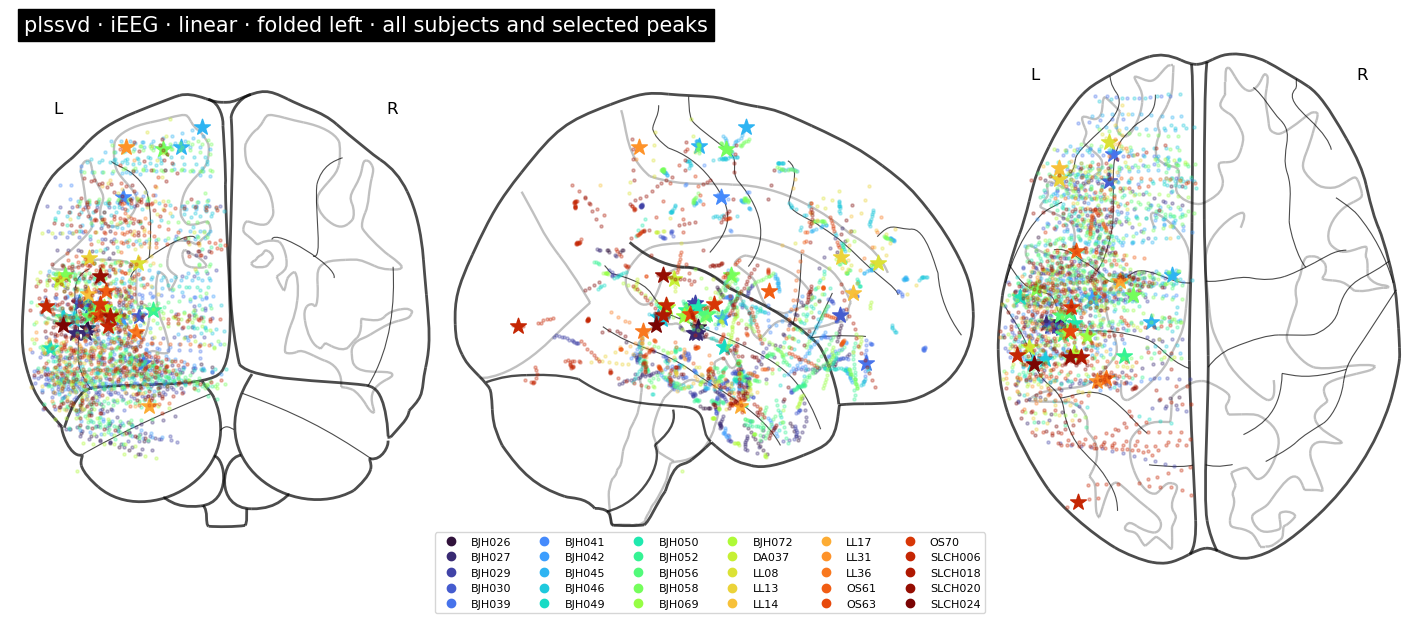

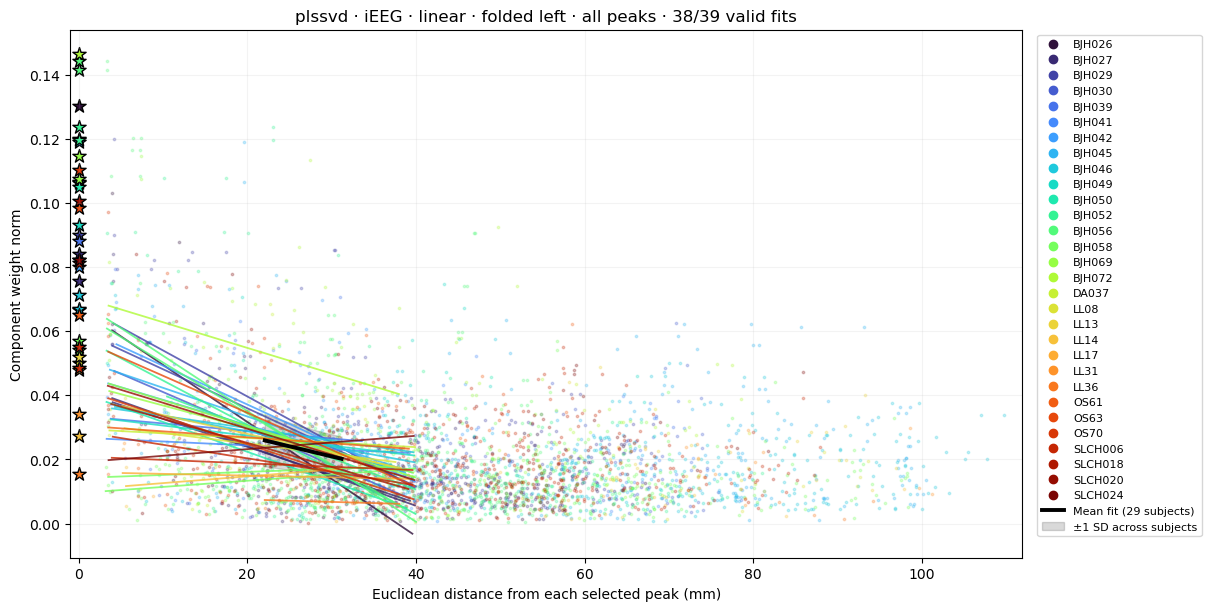

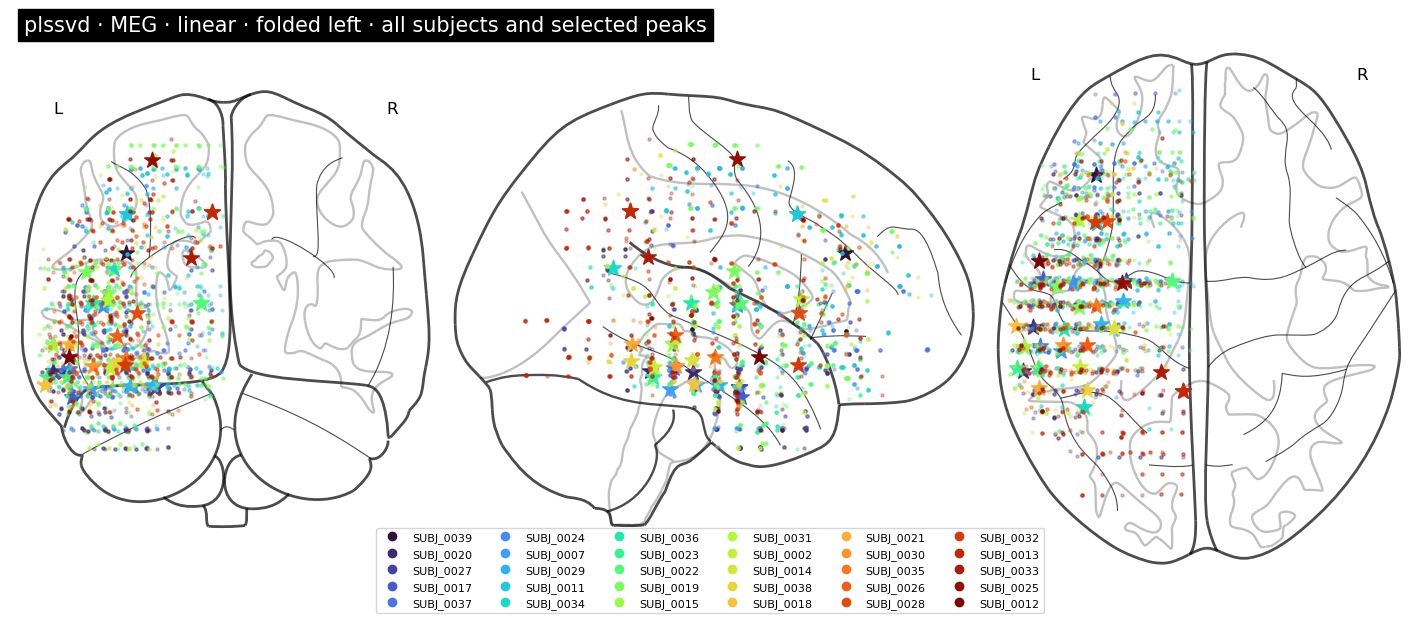

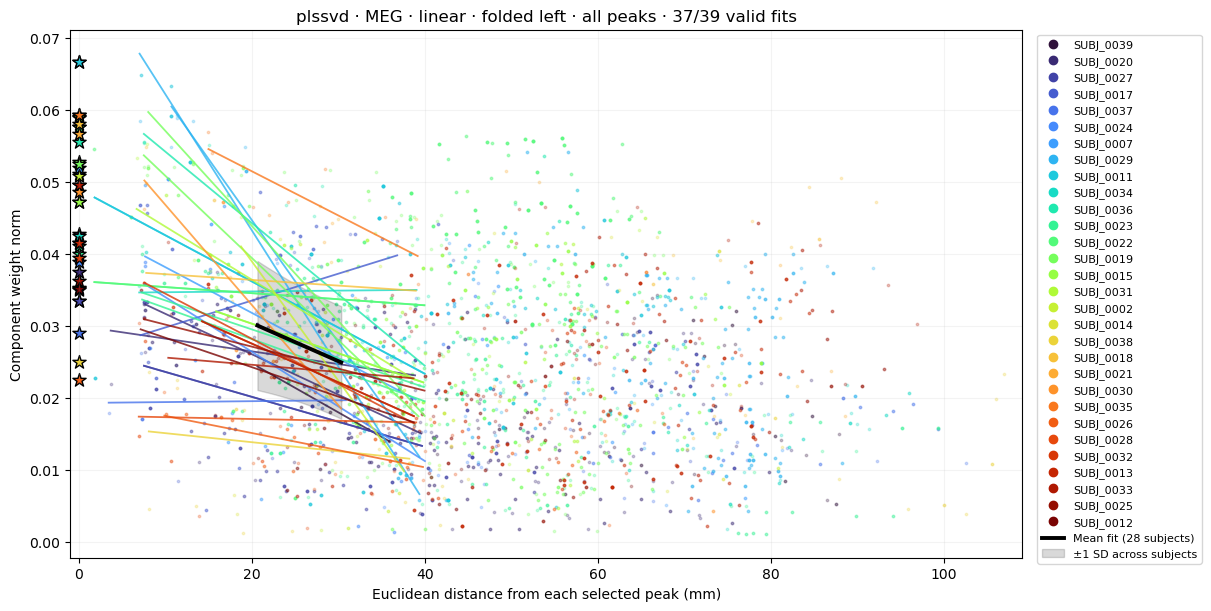

In [14]:
# Uses the model stored in gradient_results; rerun analysis after changing fit/settings.
gradient_module = importlib.reload(gradient_module)
GRADIENT_SHOW_OTHER_MAXIMA = False  # Optional red distance lines (can be dense).

for modality, scopes in gradient_results.items():
    gradient_figures = gradient_module.plot_combined_gradients(
        scopes, title=f'{MODEL} · {modality}',
        show_other_maxima=GRADIENT_SHOW_OTHER_MAXIMA)
    for figure in gradient_figures.values():
        display(figure)
        plt.close(figure)


modality  fit_status       
MEG       insufficient_data     2
          ok                   37
iEEG      insufficient_data     1
          ok                   38
Name: n_peak_fits, dtype: int64

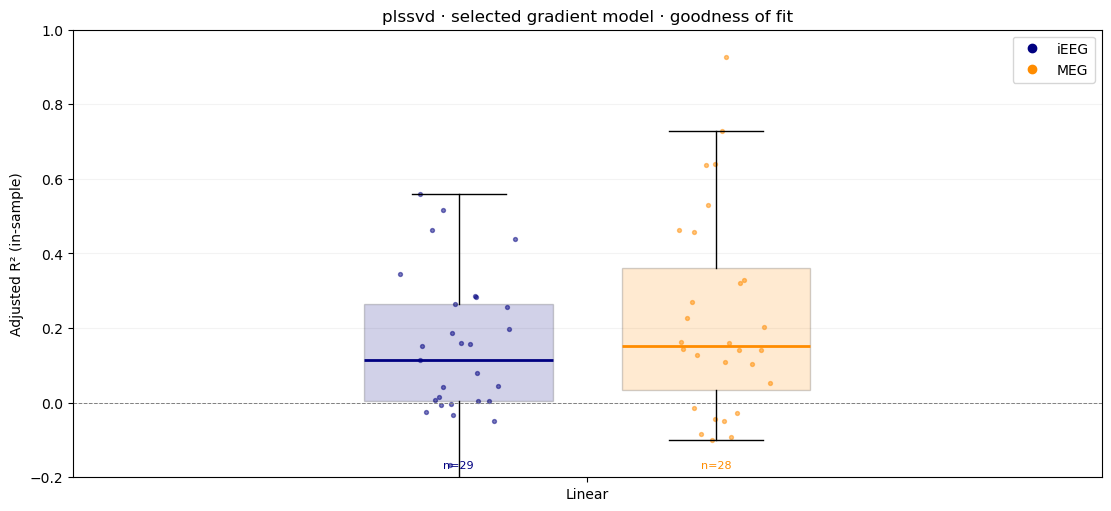

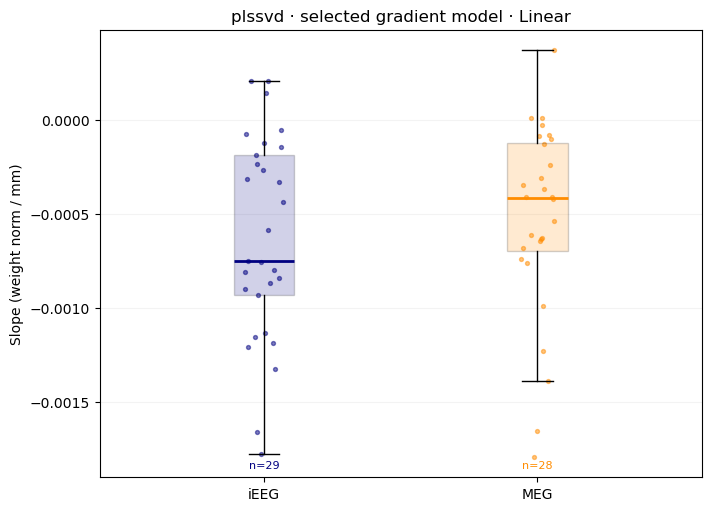

In [15]:
# Descriptive summaries of the selected model, without refitting.
import pandas as pd

gradient_metric_frames = []
for modality, scopes in gradient_results.items():
    for scope, result in scopes.items():
        if result['fits'].empty:
            continue
        frame = result['fits'].copy()
        frame['model'] = result.get('fit_model', 'gaussian')
        frame['modality'], frame['scope'] = modality, scope
        frame['within_subject'] = not result['features'].scope.eq('pooled').all()
        frame['matched_peak'] = frame.fit_status.eq('ok')
        gradient_metric_frames.append(frame)
if gradient_metric_frames:
    gradient_fit_metrics = pd.concat(gradient_metric_frames, ignore_index=True)
    display(gradient_fit_metrics.groupby(['modality', 'fit_status']).size().rename('n_peak_fits'))
    gradient_summary_figures = gradient_module.plot_gradient_model_comparison(
        gradient_fit_metrics, models=tuple(gradient_fit_metrics.model.unique()),
        title=f'{MODEL} · selected gradient model')
    for figure in gradient_summary_figures.values():
        display(figure)
        plt.close(figure)
else:
    print('No selected maxima to summarize.')


### Exploratory selection of gradient radii
The following cell searches `GRADIENT_RADIUS_MM` (peak-selection neighborhood) and `GRADIENT_FIT_RADIUS_MM` (point-inclusion radius) on editable 10–100 mm grids. The figure has one panel per modality: **x = inclusion radius, y = peak-selection radius, color = mean adjusted R² for the selected model**. Color limits are shared across modalities; all finite estimates are colored; × marks limited support, and gray means the metric is undefined. White stars identify suggested pairs without changing the main Gradient settings. The cell has independent scope, component, hemisphere, and support settings. Numeric neighborhood radii select local maxima rather than the top-percentage mode.

**Selected-model fit quality.** Choose `RADIUS_FIT_MODEL` at the top of the cell: `linear` ($b+md$), `quadratic` ($b-cd^2$, $c\geq0$, second order with its maximum at the peak), `gaussian` ($b+a\exp[-d^2/(2\sigma^2)]$), or `exponential` ($b+a\exp[-d/\tau]$). Maximize mean $R^2_{adj}=1-(1-R^2)(n-1)/(n-p)$, with $p=2$ for linear/quadratic and $p=3$ for Gaussian/exponential. The linear slope is unconstrained; Gaussian/exponential baseline and amplitude are nonnegative. Negative scores are retained. Exact ties favor smaller neighborhood and inclusion radii. This is in-sample optimization across different domains and peak sets, not a validated biological optimum; small domains can be easier to fit.

The metric averages valid peaks equally in pooled analysis. Within-subject analysis first averages peaks within each subject, then averages subjects equally. For automatic recommendations, defaults require at least three peaks with six or more observations and 80% coverage by those supported peaks. Exploratory evaluations use all computable peaks: at least three observations at two or more distinct distances for linear/quadratic; Gaussian/exponential retain six observations at four or more distinct distances for nonlinear-fit stability. Limited-support estimates are displayed with × but are excluded from automatic recommendations. Constant magnitudes, absence of selected peaks, or insufficient observations can still leave values undefined; flat no-decay quadratic solutions remain excluded. Support tables include peak counts, subject/peak analysis-unit counts, and point counts. Peak identities and support change across radius pairs, and neighborhoods overlap. Inspect counts and boundary selections before copying suggested values into the main Gradient configuration. Modalities can suggest different pairs.


In [28]:
# Independent radius search; leaves the main Gradient settings unchanged.
RADIUS_FIT_MODEL = 'quadratic'  # 'linear', 'quadratic' (order 2), 'gaussian', 'exponential'
import numpy as np
RADIUS_NEIGHBORHOOD_RADII_MM = np.arange(10., 101., 10.)
RADIUS_FIT_RADII_MM = np.arange(10., 101., 10.)
RADIUS_SCOPE = 'within_subject'  # 'pooled' or 'within_subject'
RADIUS_N_COMPONENTS = 2
RADIUS_FOLD_HEMISPHERES = True
RADIUS_TARGET_HEMISPHERE = 'left'  # Reflection retains both sides.
RADIUS_MODALITIES = ('iEEG', 'MEG')
RADIUS_MAX_PEAKS = None  # Optional strongest-peak cap per scope.
RADIUS_MIN_POINTS = 6
RADIUS_MIN_PEAKS = 3
RADIUS_MIN_VALID_FRACTION = .8

import importlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import vs3_1_gradients as radius_gradient_module
radius_gradient_module = importlib.reload(radius_gradient_module)
import vs3_1_gradient_radius_search as radius_module
radius_module = importlib.reload(radius_module)

radius_search_results, radius_search_candidates = {}, {}
for modality in RADIUS_MODALITIES:
    print(f'{modality}: starting {RADIUS_FIT_MODEL} radius search')
    radius_search_results[modality] = radius_module.radius_search(
        weights[modality], datasets[modality].metadata,
        neighborhood_radii=RADIUS_NEIGHBORHOOD_RADII_MM,
        fit_radii=RADIUS_FIT_RADII_MM, metric=RADIUS_FIT_MODEL,
        n_components=RADIUS_N_COMPONENTS, spatial_scope=RADIUS_SCOPE,
        fold_hemispheres=RADIUS_FOLD_HEMISPHERES,
        target_hemisphere=RADIUS_TARGET_HEMISPHERE,
        max_peaks=RADIUS_MAX_PEAKS, min_points=RADIUS_MIN_POINTS,
        min_peaks=RADIUS_MIN_PEAKS, min_valid_fraction=RADIUS_MIN_VALID_FRACTION,
        progress=print)
    radius_search_candidates[modality] = radius_module.select_radius_candidates(
        radius_search_results[modality]['grid'])
    candidates = radius_search_candidates[modality]
    if candidates.empty:
        print(f'{modality}: no supported candidate; inspect the grid and support counts.')
    else:
        print(f'{modality}: suggested pair (not applied to Gradient settings)')
        display(candidates.head(1))
        if bool(candidates.iloc[0].boundary):
            print('Selection lies on a grid boundary; inspect sensitivity to the search range.')

radius_search_support = pd.concat(
    [r['grid'].assign(modality=m) for m, r in radius_search_results.items()], ignore_index=True)
display(radius_search_support)
radius_search_figure = radius_module.plot_radius_search(
    radius_search_results, candidates=radius_search_candidates,
    title=f'{RADIUS_FIT_MODEL.capitalize()} radius search · {RADIUS_SCOPE} · '
          f'folded={RADIUS_FOLD_HEMISPHERES} ({RADIUS_TARGET_HEMISPHERE}) · × = limited support; gray = undefined')
display(radius_search_figure)
plt.close(radius_search_figure)


iEEG: starting quadratic radius search


### Exploratory selection of top percentage and fitting radius
This independent cell uses **`GRADIENT_RADIUS_MM=None`** and searches the top percentage of weight magnitudes together with the fitting radius. The default percentage grid is 0.5, 1, 2, 3, 5, 7.5, and 10%; the fitting-radius grid is 10–100 mm. Edit both grids below. Each figure has one panel per modality: **x = fitting radius, y = top percentage, color = mean adjusted R²**. The existing 0–1 color scale is retained; negative scores remain in the tables and use the lowest color.

Top percentages are applied within each analysis scope, with the selected count rounded upward and zero magnitudes excluded. These selected features are not necessarily spatial local maxima. The fit model, hemisphere settings, scope, and support rules are independent of the preceding cell. All finite estimates are displayed; × marks limited support and gray marks undefined estimates. Recommendations maximize supported mean adjusted R², with smaller percentages and radii breaking exact ties. Within-subject results average peaks within subjects and then average subjects equally.

Suggested settings are not automatically applied to the main Gradient configuration. To use them, set `GRADIENT_RADIUS_MM=None`, then copy the recommended `top_percent` and `fit_radius_mm` values. Adjacent percentage settings may select identical features in small datasets. Keep `PERCENT_SEARCH_MAX_PEAKS=None` for the complete percentage search; a cap can make distinct percentages select the same features. This is exploratory in-sample selection over changing feature subsets, not independent validation.


In [ ]:
# Independent top-percentage × fitting-radius search; leaves the main Gradient settings unchanged.
PERCENT_SEARCH_FIT_MODEL = 'quadratic'  # 'linear', 'quadratic' (order 2), 'gaussian', 'exponential'
import numpy as np
PERCENT_SEARCH_TOP_PERCENTS = np.array([.5, 1., 2., 3., 5., 7.5, 10.])  # Percent, not fraction.
PERCENT_SEARCH_FIT_RADII_MM = np.arange(10., 101., 10.)
PERCENT_SEARCH_SCOPE = 'within_subject'  # 'pooled' or 'within_subject'
PERCENT_SEARCH_N_COMPONENTS = 2
PERCENT_SEARCH_FOLD_HEMISPHERES = True
PERCENT_SEARCH_TARGET_HEMISPHERE = 'left'  # Reflection retains both sides.
PERCENT_SEARCH_MODALITIES = ('iEEG', 'MEG')
PERCENT_SEARCH_MAX_PEAKS = None  # Optional strongest-peak cap per scope.
PERCENT_SEARCH_MIN_POINTS = 6
PERCENT_SEARCH_MIN_PEAKS = 3
PERCENT_SEARCH_MIN_VALID_FRACTION = .8

import importlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import vs3_1_gradients as radius_gradient_module
radius_gradient_module = importlib.reload(radius_gradient_module)
import vs3_1_gradient_radius_search as radius_module
radius_module = importlib.reload(radius_module)

percent_search_results, percent_search_candidates = {}, {}
for modality in PERCENT_SEARCH_MODALITIES:
    print(f'{modality}: starting {PERCENT_SEARCH_FIT_MODEL} top-percentage / fitting-radius search')
    percent_search_results[modality] = radius_module.radius_search(
        weights[modality], datasets[modality].metadata,
        top_percents=PERCENT_SEARCH_TOP_PERCENTS,
        fit_radii=PERCENT_SEARCH_FIT_RADII_MM, metric=PERCENT_SEARCH_FIT_MODEL,
        n_components=PERCENT_SEARCH_N_COMPONENTS, spatial_scope=PERCENT_SEARCH_SCOPE,
        fold_hemispheres=PERCENT_SEARCH_FOLD_HEMISPHERES,
        target_hemisphere=PERCENT_SEARCH_TARGET_HEMISPHERE,
        max_peaks=PERCENT_SEARCH_MAX_PEAKS, min_points=PERCENT_SEARCH_MIN_POINTS,
        min_peaks=PERCENT_SEARCH_MIN_PEAKS, min_valid_fraction=PERCENT_SEARCH_MIN_VALID_FRACTION,
        progress=print)
    percent_search_candidates[modality] = radius_module.select_radius_candidates(
        percent_search_results[modality]['grid'])
    candidates = percent_search_candidates[modality]
    if candidates.empty:
        print(f'{modality}: no supported candidate; inspect the grid and support counts.')
    else:
        print(f'{modality}: suggested pair (not applied to Gradient settings)')
        display(candidates.head(1))
        if bool(candidates.iloc[0].boundary):
            print('Selection lies on a grid boundary; inspect sensitivity to the search range.')

percent_search_support = pd.concat(
    [r['grid'].assign(modality=m) for m, r in percent_search_results.items()], ignore_index=True)
display(percent_search_support)
percent_search_figure = radius_module.plot_radius_search(
    percent_search_results, candidates=percent_search_candidates,
    title=f'{PERCENT_SEARCH_FIT_MODEL.capitalize()} top-percentage / fitting-radius search · {PERCENT_SEARCH_SCOPE} · '
          f'folded={PERCENT_SEARCH_FOLD_HEMISPHERES} ({PERCENT_SEARCH_TARGET_HEMISPHERE}) · × = limited support; gray = undefined')
display(percent_search_figure)
plt.close(percent_search_figure)


### Compare radial models: linear, quadratic, Gaussian, and exponential
This cell has its own configuration below, independent of the earlier Gradient analysis. It recomputes peak selection and radial profiles from the existing fitted `weights` and `datasets`, using its own modalities, component count, scope, hemisphere folding/target, and fitting radius. Change these settings and rerun this cell alone. Zero-distance observations remain excluded. No group model is refitted. Hemisphere folding reflects both hemispheres onto the selected side; it does not restrict inclusion to that hemisphere.

For weight norm $A$ and distance $d$ (mm), fit:

| Model | Function | Separate parameter plot |
|---|---|---|
| Linear | $A(d)=b+md$ | Slope $m$ (weight norm/mm) |
| Quadratic | $A(d)=b-cd^2$, $c\geq0$ | Curvature $-2c$ (weight norm/mm²) |
| Gaussian | $A(d)=b+a\exp[-d^2/(2\sigma^2)]$ | Width $\sigma$ (mm) |
| Exponential | $A(d)=b+a\exp(-d/\tau)$ | Decay length $\tau$ (mm) |

The exponential allows an immediate decrease at the origin, whereas the Gaussian has zero slope there. The quadratic is constrained to have its maximum at distance zero and decrease for positive distances when $c>0$. Its height $b$ is fitted rather than fixed to the excluded observed peak. The $c=0$ boundary is flagged as `no_decay_boundary` and excluded from valid-fit summaries. Do not extrapolate beyond the fitted radius. Gaussian/exponential baseline and amplitude are nonnegative; the linear coefficients are unconstrained, and quadratic curvature is nonpositive.

The combined goodness-of-fit plot uses $R^2_{\mathrm{adj}}=1-(1-R^2)(n-1)/(n-p)$, where $R^2=1-\mathrm{SSE}/\mathrm{SST}$ and $p$ counts fitted coefficients including the intercept (2 for linear and the constrained quadratic, 3 for Gaussian and exponential). Higher values indicate better descriptive fit after a parameter-count adjustment; negative values are retained. This remains an in-sample comparison, not spatial cross-validation or a significance test.

All five figures use **matched peaks with valid fits for every requested model**; the status table reports exclusions. Dots represent individual peaks for pooled results and one median per subject for within-subject results. Boxes show medians and quartiles, with 1.5-IQR whiskers. Parameter plots characterize shape/scale, not relationship strength: larger σ or τ means slower decay; negative linear slope means decreasing amplitude; more negative quadratic curvature means faster decline away from the fixed vertex. Raw slopes/curvatures depend on weight scaling, so modality differences require caution. Peaks share observations and are not independent.

Fitting uses [SciPy nonlinear least squares](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.curve_fit.html) for decay models and linear least squares for polynomial models. See also the [definition of R²](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.r2_score.html).


Independent configuration used for this comparison:
Plots: matched peaks; within-subject results use subject medians. Parameters describe shape/scale, not association strength.


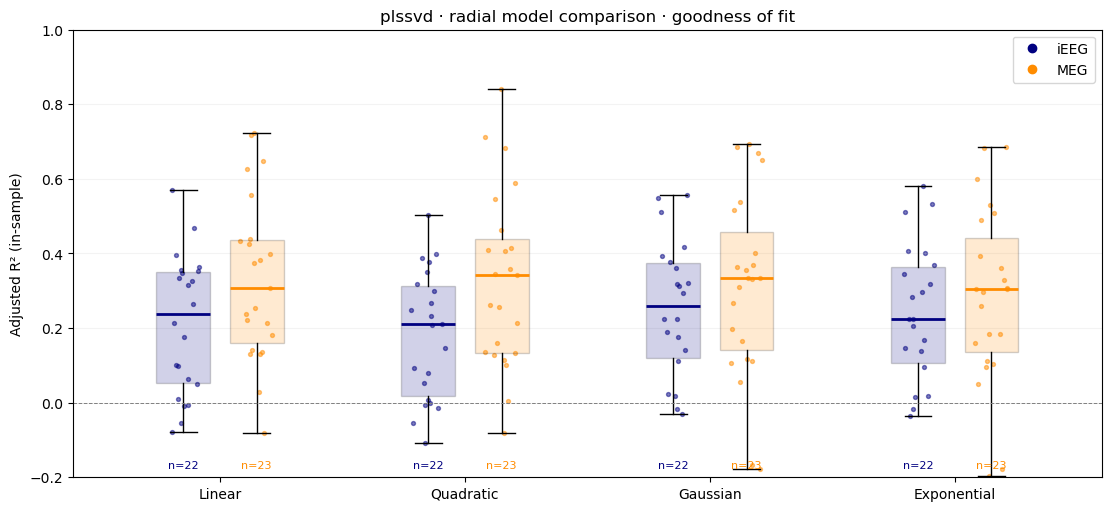

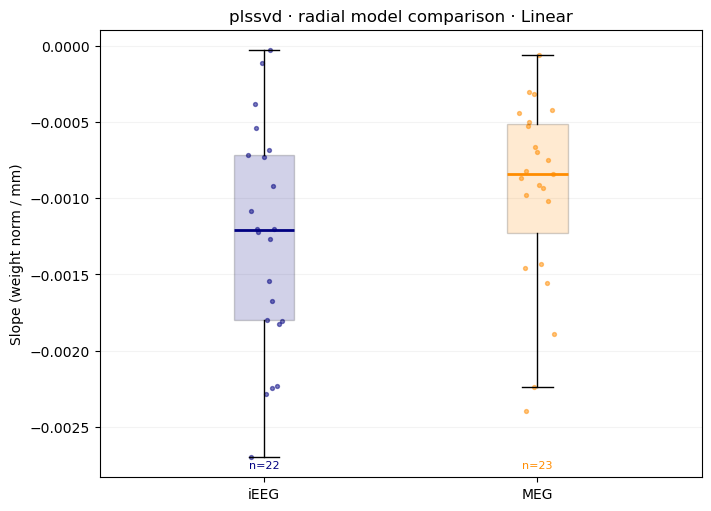

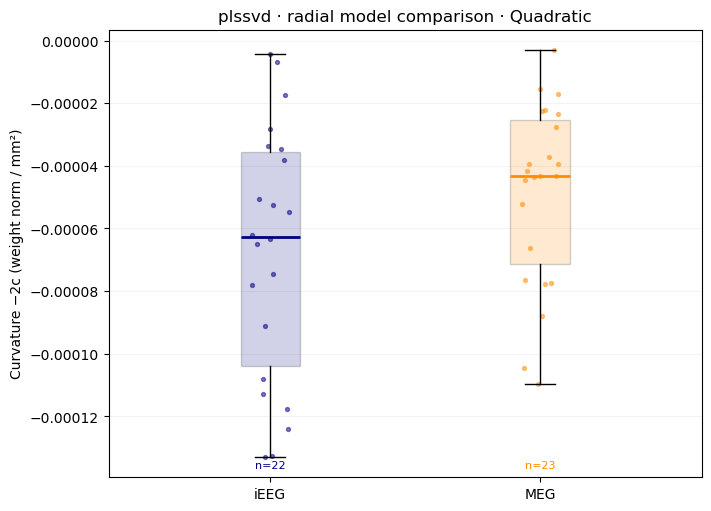

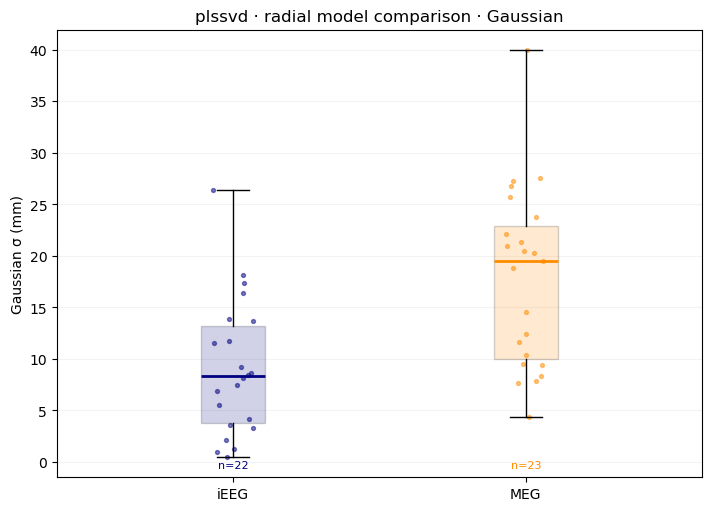

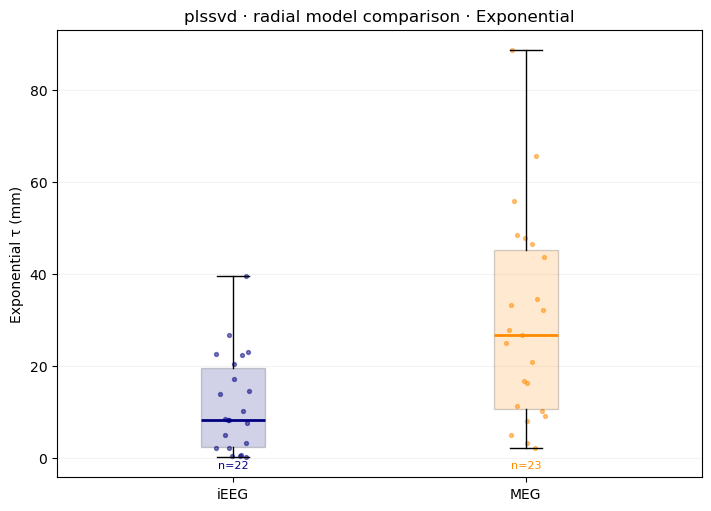

In [25]:
# Independent configuration for this comparison only.
GRADIENT_COMPARISON_SCOPE = 'within_subject'  # 'pooled' or 'within_subject'
GRADIENT_COMPARISON_FOLD_HEMISPHERES = True  # Reflect both sides; False uses original coordinates.
GRADIENT_COMPARISON_TARGET_HEMISPHERE = 'left'  # 'left' or 'right'; all features retained.
GRADIENT_COMPARISON_N_COMPONENTS = 2  # First k fitted components.
GRADIENT_COMPARISON_RADIUS_MM = 100  # Neighborhood for maxima; None uses top percentage.
GRADIENT_COMPARISON_TOP_PERCENT = 1  # Used when RADIUS_MM is None.
GRADIENT_COMPARISON_FIT_RADIUS_MM = 30.  # Include points with 0 < distance <= this radius.
GRADIENT_COMPARISON_MAX_PEAKS = None  # Optional cap per modality/scope; None uses all selected peaks.
GRADIENT_COMPARISON_MODALITIES = ('iEEG', 'MEG')
GRADIENT_COMPARISON_MODELS = ('linear', 'quadratic', 'gaussian', 'exponential')

import importlib
import matplotlib.pyplot as plt
from IPython.display import display
import vs3_1_gradients as gradient_module
gradient_module = importlib.reload(gradient_module)

# Rebuild profiles independently; preserve the earlier gradient_results.
gradient_comparison_results = {}
for modality in GRADIENT_COMPARISON_MODALITIES:
    gradient_comparison_results[modality] = gradient_module.analyze_gradients(weights[modality], datasets[modality].metadata,
        n_components=GRADIENT_COMPARISON_N_COMPONENTS,
        spatial_scope=GRADIENT_COMPARISON_SCOPE,
        neighborhood_mm=GRADIENT_COMPARISON_RADIUS_MM,
        top_percent=GRADIENT_COMPARISON_TOP_PERCENT,
        max_peaks=GRADIENT_COMPARISON_MAX_PEAKS,
        fit_radius_mm=GRADIENT_COMPARISON_FIT_RADIUS_MM,
        fold_hemispheres=GRADIENT_COMPARISON_FOLD_HEMISPHERES,
        target_hemisphere=GRADIENT_COMPARISON_TARGET_HEMISPHERE)

gradient_model_comparison = gradient_module.compare_gradient_models(gradient_comparison_results, models=GRADIENT_COMPARISON_MODELS)


if gradient_model_comparison.empty: print('No selected peak profiles. Inspect the comparison peak-selection settings above.')
else:
    print('Independent configuration used for this comparison:')
    #display(gradient_model_comparison[['modality', 'within_subject', 'fold_hemispheres', 'target_hemisphere','fit_radius_mm', 'n_components']].drop_duplicates())
    #display(gradient_model_comparison.groupby(['modality', 'model', 'fit_status']).size().rename('n_peak_fits').reset_index())
    gradient_matched_peaks = gradient_model_comparison.drop_duplicates(['modality', 'scope', 'peak_id'])
    #display(gradient_matched_peaks.groupby('modality').agg(selected_peaks=('matched_peak', 'size'), matched_valid_peaks=('matched_peak', 'sum')))
    if not gradient_model_comparison.matched_peak.any(): print('No peaks have valid fits for all requested models; figures contain no estimates.')
    print('Plots: matched peaks; within-subject results use subject medians. Parameters describe shape/scale, not association strength.')
    
    gradient_comparison_figures = gradient_module.plot_gradient_model_comparison(gradient_model_comparison, models=GRADIENT_COMPARISON_MODELS,title=f'{MODEL} · radial model comparison')
    
    for figure in gradient_comparison_figures.values():
        display(figure)
        plt.close(figure)


## Clustering absolute model weights
Clustering uses **absolute weights of the first `WEIGHT_N_COMPONENTS` components**, separately for each modality, without spatial coordinates or axis standardization. Thresholding is **off by default**. When enabled, magnitudes below the component-specific mean + population SD are set to zero. All-zero profiles are excluded (label −1) and shown gray on the brain. Component signs are discarded; cluster labels are not matched across methods or modalities.

Export the existing fitted weights once below. Run the printed command in a terminal or cluster job: all cluster fitting and summary computation occur in `vs3_1_weight_clustering.py`. No group-model refit is needed. Subsequent plotting only loads saved results. Re-export and recompute if the model or its input data change.

Available methods: **kmeans** (Euclidean partitions), **minibatch** (scalable approximate K-means), **gmm** (full-covariance Gaussian mixture, hard maximum-probability assignments), and **birch** (hierarchical compression followed by clustering). BIRCH may return fewer clusters than requested. Its threshold is a fraction of the RMS input-vector norm (default 0.1). All methods use the same magnitude geometry; cluster count is exploratory.

Automatic selection (`WEIGHT_N_CLUSTERS = "auto"`) fits candidate counts 2–10 separately for each modality and method, choosing the highest Euclidean silhouette score. Fits use all nonzero profiles; scores use a fixed seeded sample of at most 2,000 features to limit memory. Exact ties favor smaller counts. Inspect the saved score curve, particularly boundary selections. This criterion favors compact, separated groups and does not test whether clustering exists; it can also be less appropriate for elongated Gaussian-mixture clusters. Use an integer to retain manual selection.

`WEIGHT_N_COMPONENTS` controls both fitting and silhouette scoring. Export includes all fitted components, so changing this setting requires only rerunning clustering, not the group model (provided enough components were fitted). The weight-space figure is 2D for two components and 3D for three or more components (displaying only the first three axes). For one component, the second display axis is zero. Results are stored separately by component count. Re-export once if using older three-component exports.


In [18]:
from vs3_1_weight_clustering import export_inputs, load_results, plot_results, result_directory
import shlex
N_COMPONENTS = 6
WEIGHT_COMPONENT_COUNTS = list(range(2, N_COMPONENTS + 1))  # Counts for the summary sweep.
WEIGHT_N_COMPONENTS = 2  # First N fitted components; must be <= N_COMPONENTS.
WEIGHT_N_CLUSTERS = 'auto'  # Use an integer for a fixed count.
WEIGHT_K_MIN = 2
WEIGHT_K_MAX = 10
WEIGHT_USE_THRESHOLDED = False
WEIGHT_METHODS = ['kmeans', 'minibatch', 'gmm', 'birch']
WEIGHT_METHOD = 'kmeans'  # Choose a computed method for plotting.
WEIGHT_CLUSTER_INPUT = OUTPUT / 'absolute_weight_clustering'

# Export only: uses the existing fitted weights and shared coordinate labels.
export_inputs(weights, coverage_region_metadata, WEIGHT_CLUSTER_INPUT)
command = ['python', '-u', str(ROOT / 'vs3_1_weight_clustering.py'),
           '--input-dir', str(WEIGHT_CLUSTER_INPUT), '--n-clusters', str(WEIGHT_N_CLUSTERS),
           '--n-components', str(WEIGHT_N_COMPONENTS), '--k-min', str(WEIGHT_K_MIN), '--k-max', str(WEIGHT_K_MAX),
           '--seed', str(SEED), '--methods', *WEIGHT_METHODS]
if WEIGHT_USE_THRESHOLDED:
    command.append('--threshold')
print('Run outside the notebook before plotting:\n' + ' submit_to_cluster -n 2 -q short.q "' + shlex.join(command) + '" --project MINDLAB2021_MEG-TempSeqAges')
# Automatic-selection sweep for the cross-method/component summary below.
# Run these commands outside the notebook; existing group models are reused.
print('\nComponent-count sweep (automatic cluster selection):')
for dimensions in WEIGHT_COMPONENT_COUNTS:
    sweep_command = command.copy()
    sweep_command[sweep_command.index('--n-components') + 1] = str(dimensions)
    sweep_command[sweep_command.index('--n-clusters') + 1] = 'auto'
    print('submit_to_cluster -n 2 -q short.q "' + shlex.join(sweep_command)
          + '" --project MINDLAB2021_MEG-TempSeqAges')


Run outside the notebook before plotting:
 submit_to_cluster -n 2 -q short.q "python -u /users/barbara/Desktop/MIB_iEEG/iEEGvsMEG/vs3_1_weight_clustering.py --input-dir /users/barbara/Desktop/MIB_iEEG/iEEGvsMEG/out/modality_specificity/paired_coverage/plssvd/absolute_weight_clustering --n-clusters auto --n-components 2 --k-min 2 --k-max 10 --seed 2026 --methods kmeans minibatch gmm birch" --project MINDLAB2021_MEG-TempSeqAges

Component-count sweep (automatic cluster selection):
submit_to_cluster -n 2 -q short.q "python -u /users/barbara/Desktop/MIB_iEEG/iEEGvsMEG/vs3_1_weight_clustering.py --input-dir /users/barbara/Desktop/MIB_iEEG/iEEGvsMEG/out/modality_specificity/paired_coverage/plssvd/absolute_weight_clustering --n-clusters auto --n-components 2 --k-min 2 --k-max 10 --seed 2026 --methods kmeans minibatch gmm birch" --project MINDLAB2021_MEG-TempSeqAges
submit_to_cluster -n 2 -q short.q "python -u /users/barbara/Desktop/MIB_iEEG/iEEGvsMEG/vs3_1_weight_clustering.py --input-dir /us

### Clustering summary across algorithms and component counts
Run the component-count sweep above, then load the saved automatic-selection results here. Each column represents one modality; rows show the selected cluster count and its silhouette score. Missing runs appear as gaps and are listed below. Silhouette values describe separation in different dimensional spaces and are exploratory, not a test of biological validity. The individual plots below still use `WEIGHT_N_COMPONENTS` and `WEIGHT_METHOD`.


,modality,method,n_components,n_clusters,silhouette,status
0,iEEG,kmeans,2,2,0.613822,ok
1,MEG,kmeans,2,3,0.441312,ok
2,iEEG,kmeans,3,2,0.609255,ok
3,MEG,kmeans,3,4,0.337776,ok
4,iEEG,kmeans,4,2,0.596893,ok
5,MEG,kmeans,4,5,0.268652,ok
6,iEEG,kmeans,5,2,0.623278,ok
7,MEG,kmeans,5,7,0.220238,ok
8,iEEG,kmeans,6,2,0.568587,ok
9,MEG,kmeans,6,7,0.192145,ok


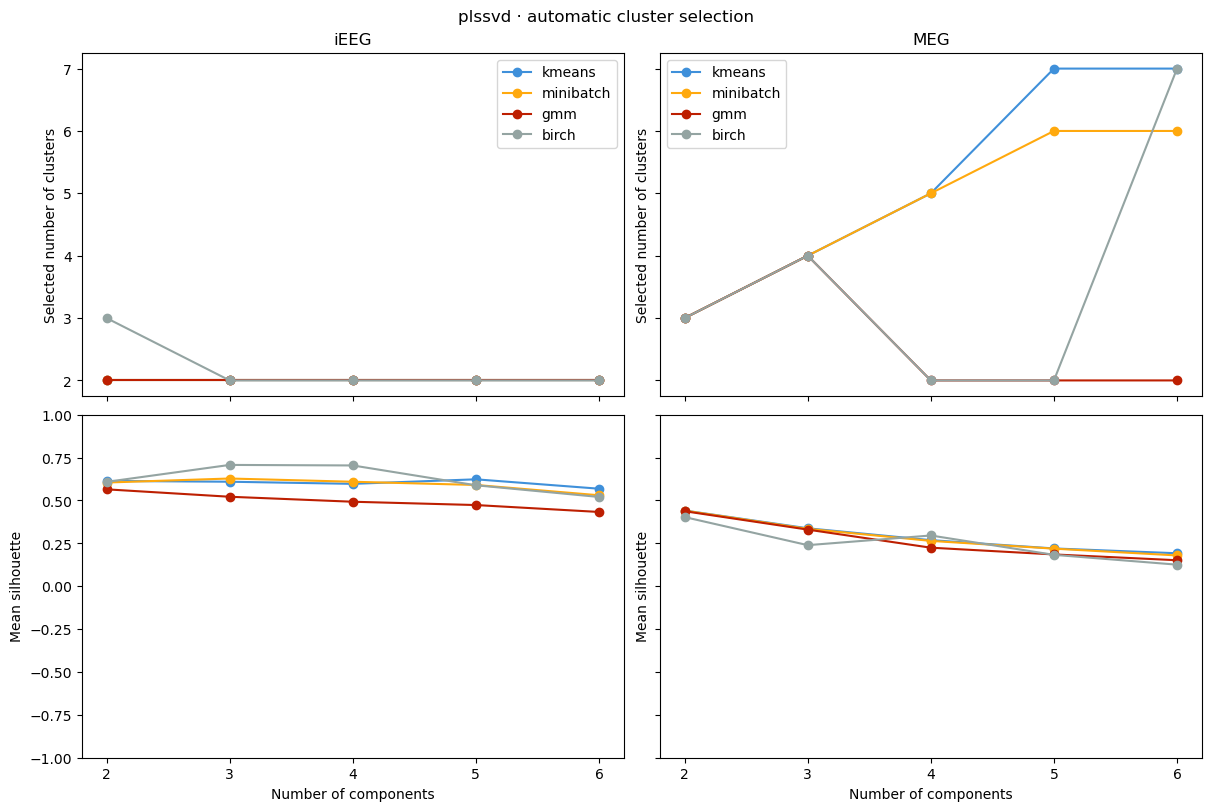

In [19]:
from vs3_1_weight_clustering import summarize_clustering, plot_clustering_summary

clustering_summary = summarize_clustering(
    WEIGHT_CLUSTER_INPUT, WEIGHT_COMPONENT_COUNTS, WEIGHT_METHODS,
    use_thresholded=WEIGHT_USE_THRESHOLDED)
display(clustering_summary)
missing_runs = clustering_summary.query("status != 'ok'")
if not missing_runs.empty:
    print('Missing runs (run the corresponding sweep commands):')
    display(missing_runs[['modality', 'method', 'n_components', 'status']])
summary_figure = plot_clustering_summary(clustering_summary, title=f'{MODEL} · automatic cluster selection')
summary_mode = 'thresholded' if WEIGHT_USE_THRESHOLDED else 'unthresholded'
clustering_summary.to_csv(WEIGHT_CLUSTER_INPUT / f'clustering_summary_{summary_mode}.csv', index=False)
summary_figure.savefig(WEIGHT_CLUSTER_INPUT / f'clustering_summary_{summary_mode}.png', dpi=180, bbox_inches='tight')
display(summary_figure)
plt.close(summary_figure)


### Plot saved clusters
Run the printed command first, then execute this cell. Change `WEIGHT_METHOD` to inspect another computed method without fitting again.

1. **2D/3D absolute-weight space:** points are native features; stars are arithmetic member means.
2. **Brain map:** one spatial centroid per cluster per populated hemisphere (left x < 0; right x > 0). Midline members are plotted but excluded from both centroids. This section always uses bilateral coordinates, independently of earlier hemisphere-folding settings.
3. **Regional contribution:** categorical histograms show the percentage of each cluster's features in each shared anatomical region. Counts are saved in the result tables. These reflect sampling coverage as well as cluster composition; they are not regional enrichment tests. Every native feature receives equal weight.


,k,actual_k,silhouette,selected,n_scored,status
0,2,2,0.613822,True,2000,ok
1,3,3,0.495378,False,2000,ok
2,4,4,0.431422,False,2000,ok
3,5,5,0.428810,False,2000,ok
4,6,6,0.423708,False,2000,ok
5,7,7,0.374288,False,2000,ok
6,8,8,0.391035,False,2000,ok
7,9,9,0.381452,False,2000,ok
8,10,10,0.385082,False,2000,ok


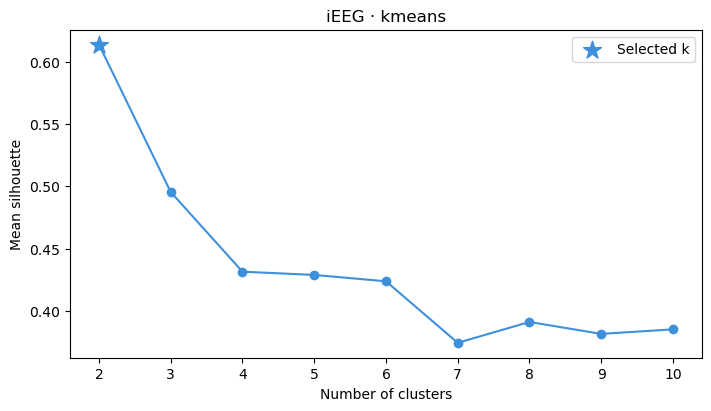

iEEG: 2576 clustered; 0 zero profiles excluded


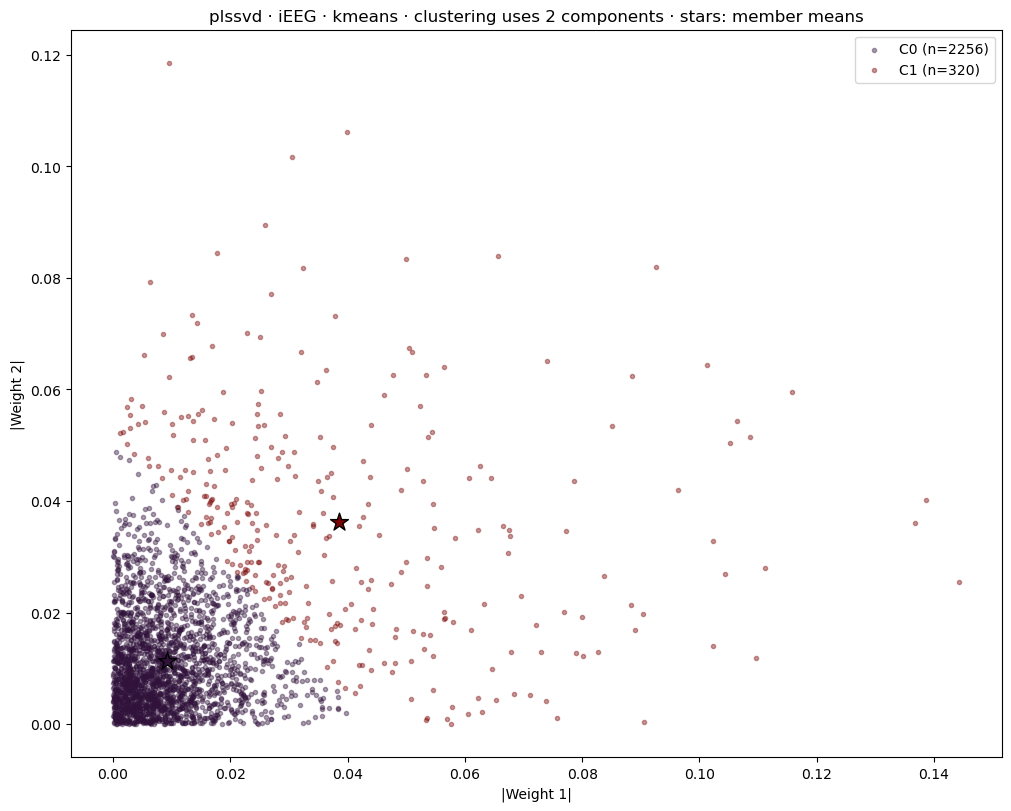

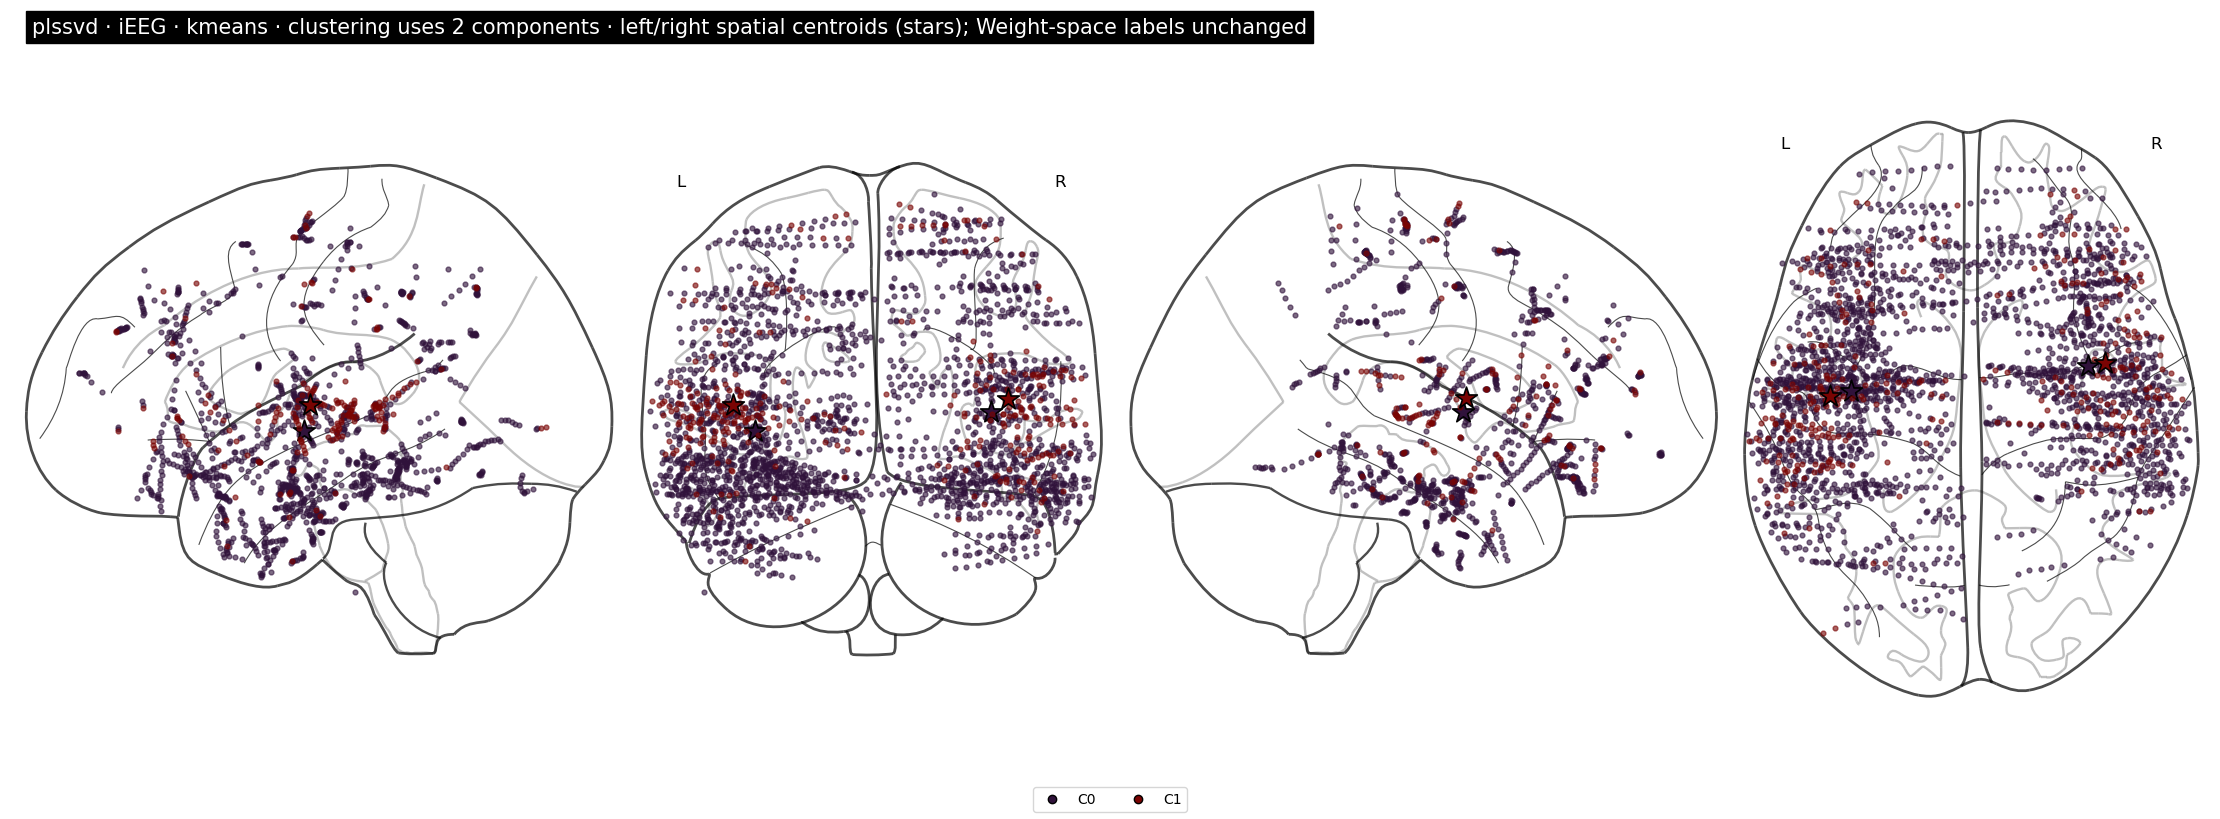

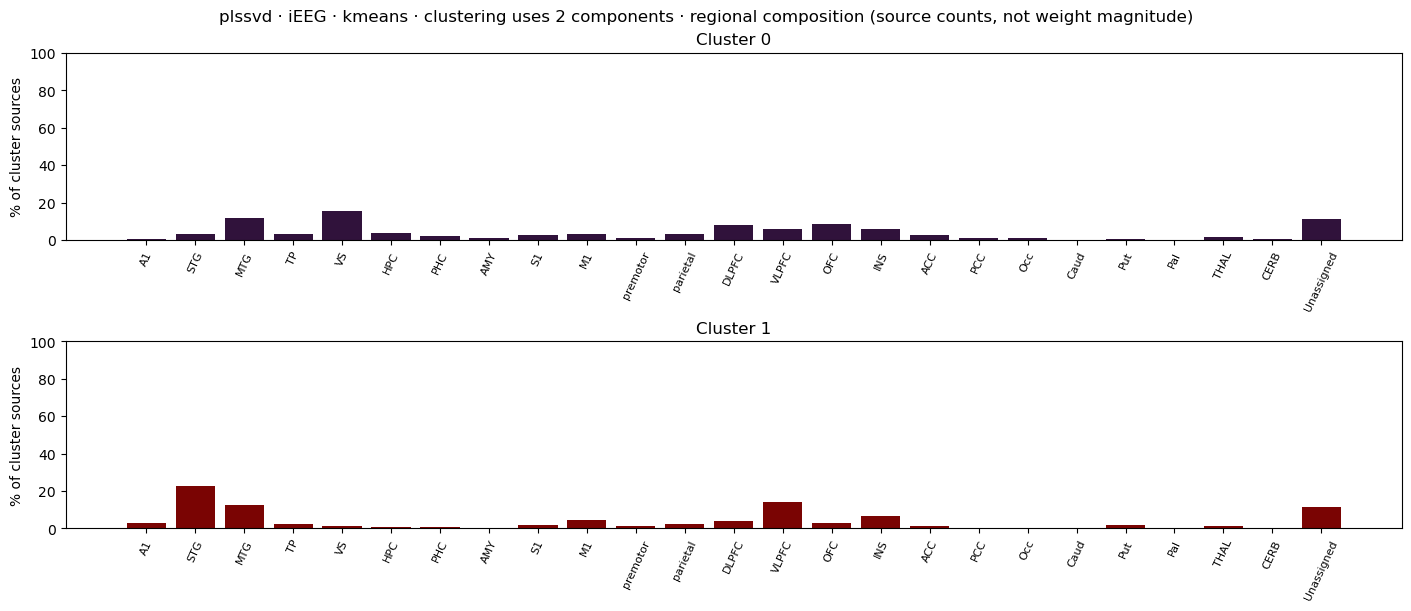

,k,actual_k,silhouette,selected,n_scored,status
0,2,2,0.354789,False,2000,ok
1,3,3,0.441312,True,2000,ok
2,4,4,0.369699,False,2000,ok
3,5,5,0.350506,False,2000,ok
4,6,6,0.365393,False,2000,ok
5,7,7,0.353215,False,2000,ok
6,8,8,0.348594,False,2000,ok
7,9,9,0.355990,False,2000,ok
8,10,10,0.357141,False,2000,ok


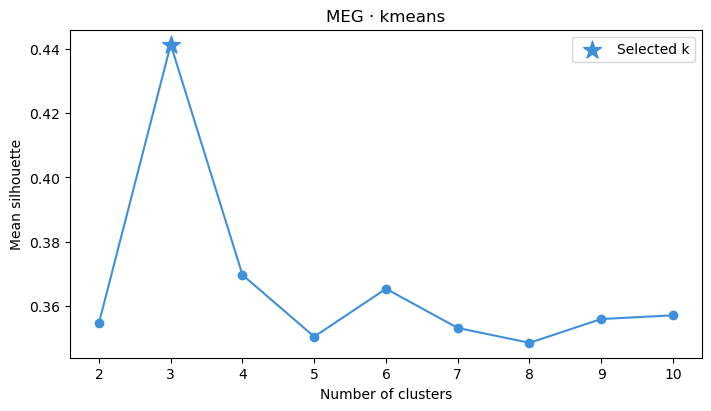

MEG: 2576 clustered; 0 zero profiles excluded


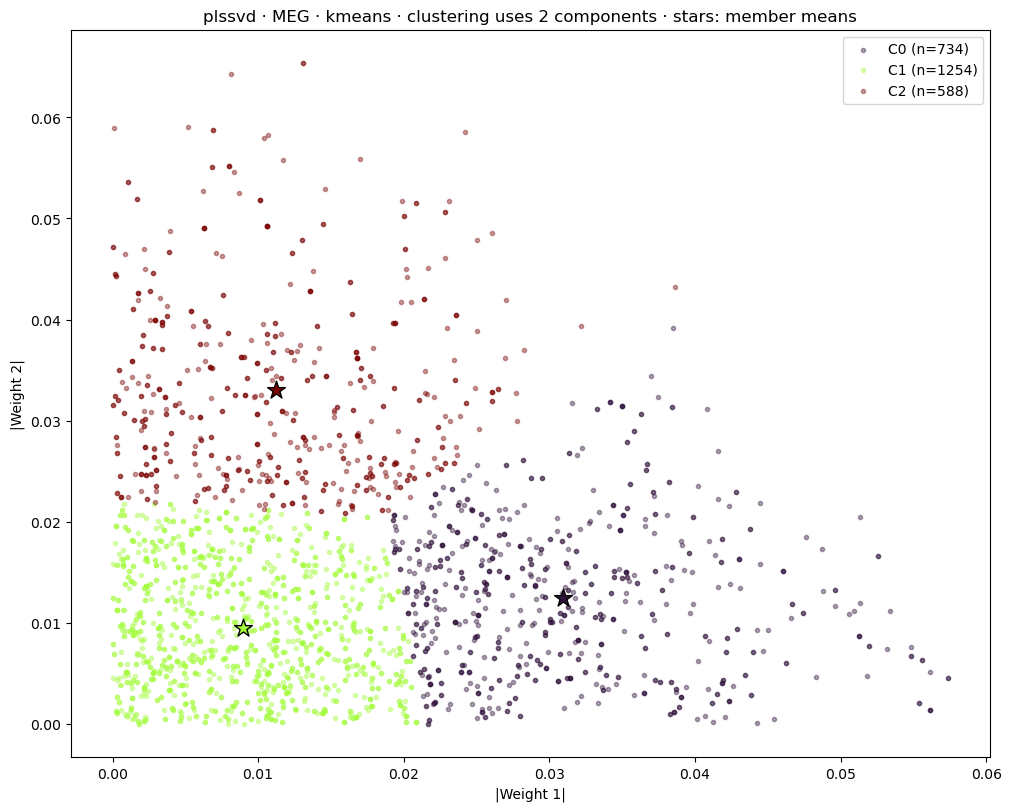

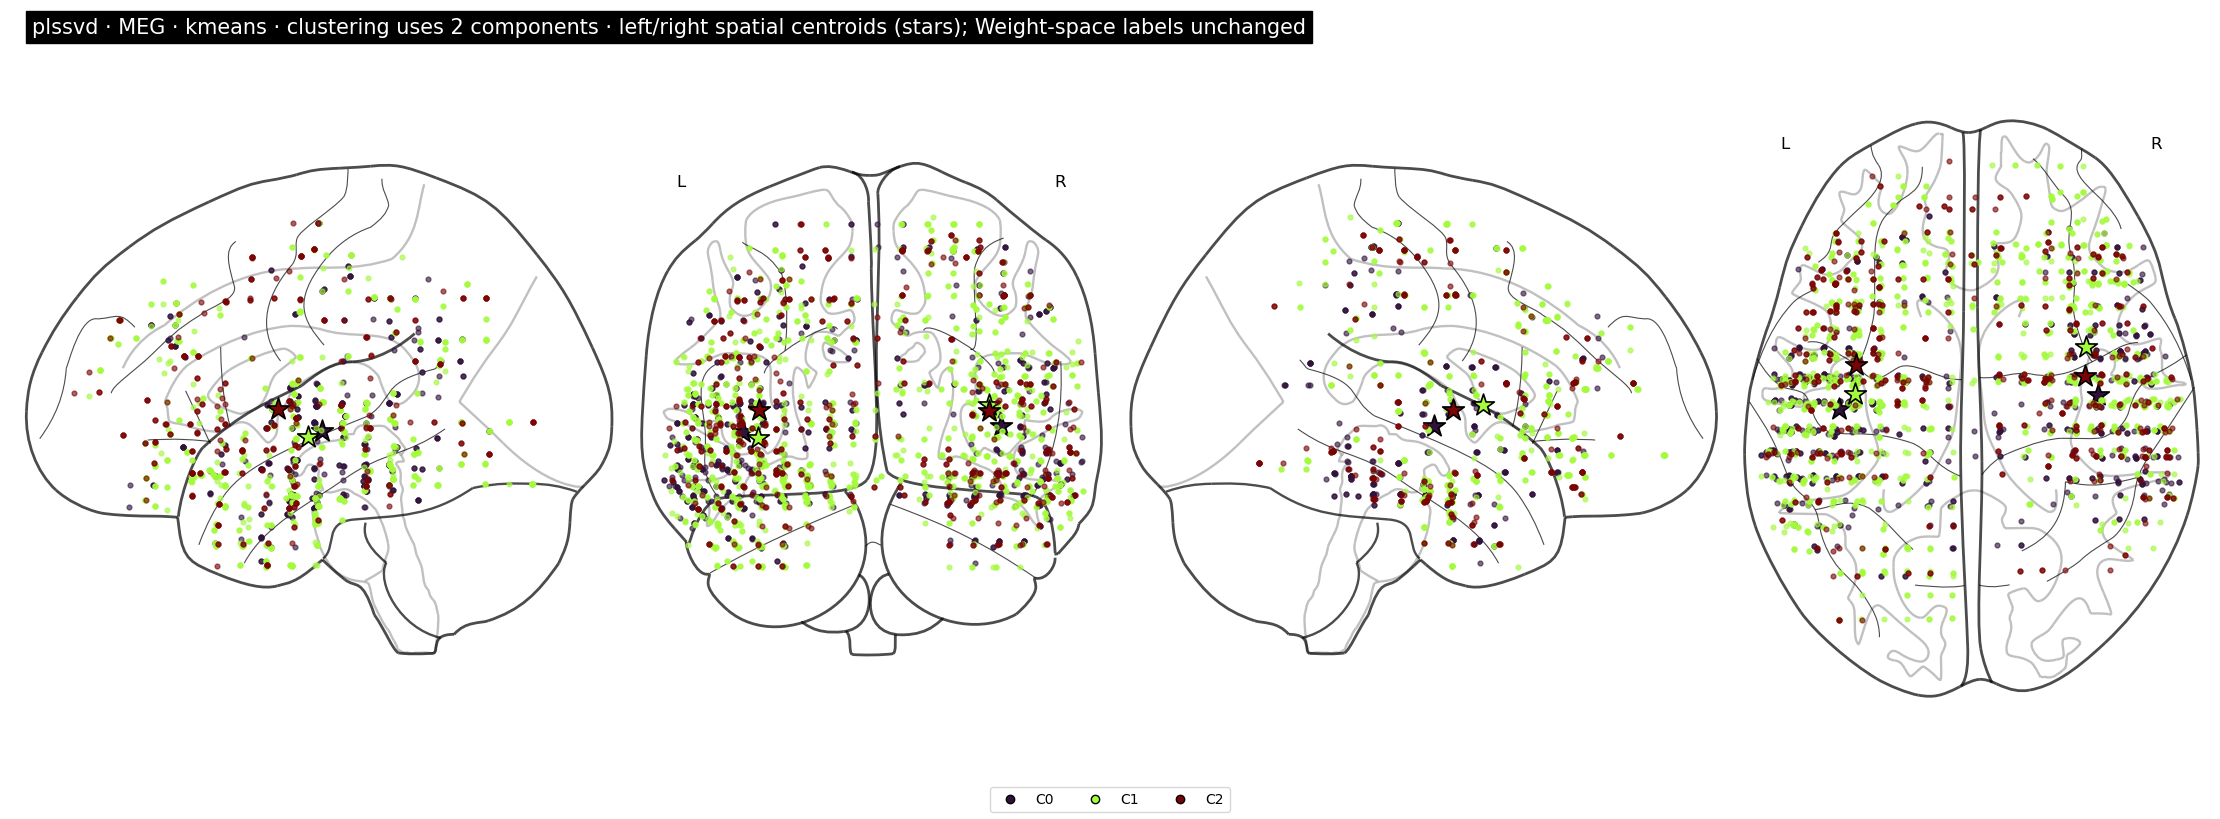

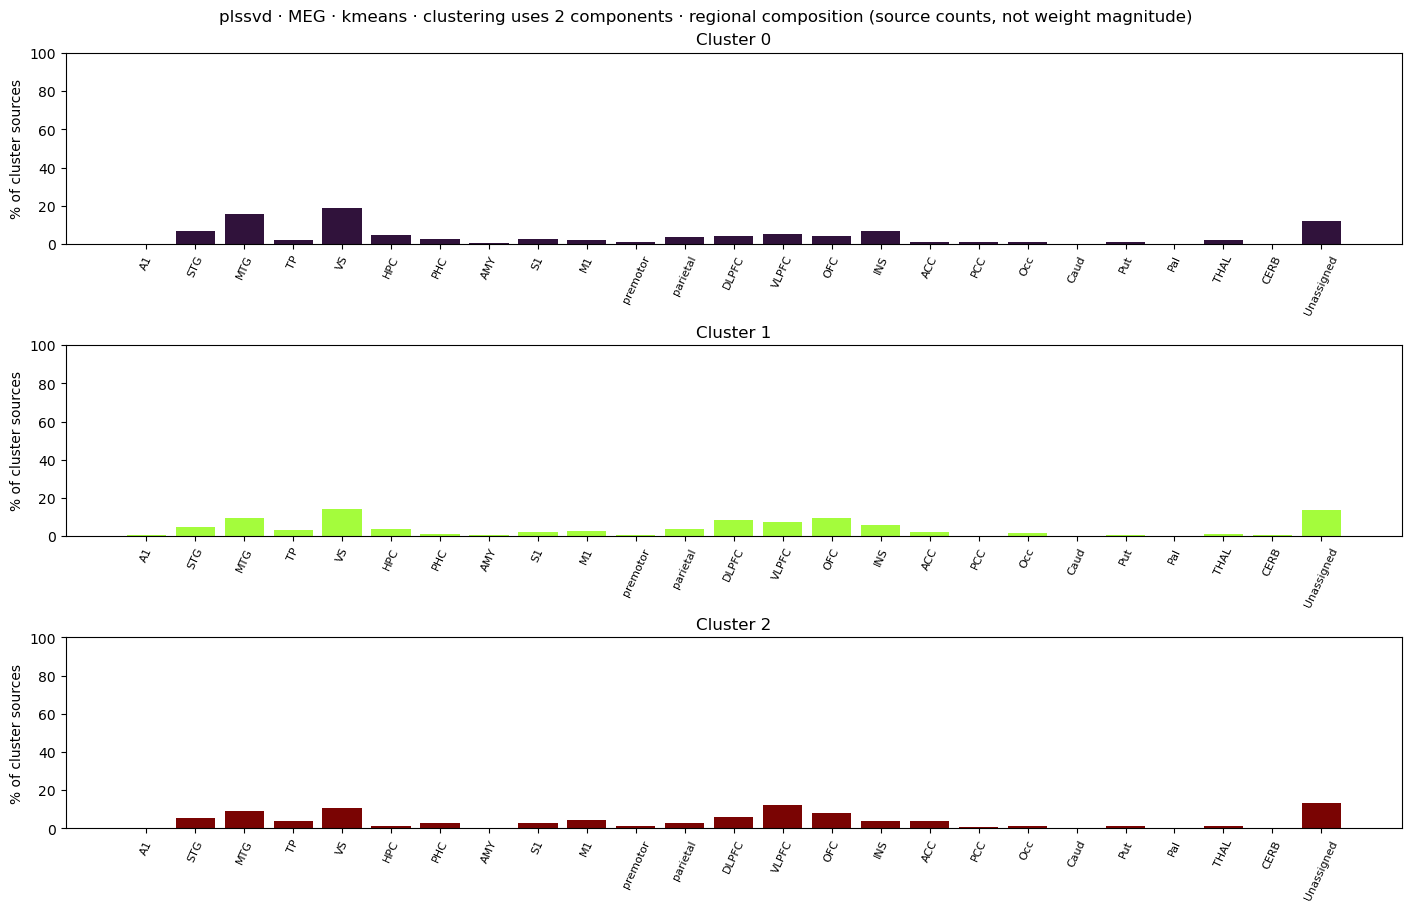

In [20]:
from vs3_1_weight_clustering import plot_cluster_selection

cluster_results = load_results(WEIGHT_CLUSTER_INPUT, WEIGHT_METHOD,
    n_clusters=WEIGHT_N_CLUSTERS, use_thresholded=WEIGHT_USE_THRESHOLDED, n_components=WEIGHT_N_COMPONENTS)
cluster_output = result_directory(WEIGHT_CLUSTER_INPUT, WEIGHT_METHOD,
    WEIGHT_N_CLUSTERS, WEIGHT_USE_THRESHOLDED, n_components=WEIGHT_N_COMPONENTS)
for modality, result in cluster_results.items():
    if 'cluster_selection' in result:
        display(result['cluster_selection'])
        selection_fig = plot_cluster_selection(result, f'{modality} · {WEIGHT_METHOD}')
        selection_fig.savefig(cluster_output / modality / 'cluster_selection.png', dpi=180)
        display(selection_fig)
        plt.close(selection_fig)
    members = result['memberships']
    print(f'{modality}: {(members.cluster_id >= 0).sum()} clustered; '
          f'{(members.cluster_id < 0).sum()} zero profiles excluded')
    for name, figure in plot_results(result, title=f'{MODEL} · {modality} · {WEIGHT_METHOD}').items():
        figure.savefig(cluster_output / modality / f'{name}.png', dpi=180, bbox_inches='tight')
        display(figure)
        plt.close(figure)
